<a href="https://colab.research.google.com/github/arraks1307/python-ai-course/blob/main/homework/lesson-13/solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Урок 13. Классификация: как предсказать категорию?

В этом ноутбуке собраны объяснения и выполненные примеры урока, задания для работы на занятии и домашняя работа. После занятия продолжайте работу **в этом же файле**. Готовых решений домашних заданий в нём нет.


**Что делает следующая ячейка.** Подключает `display` для показа таблиц и задаёт крупный текст на белом фоне. `HTML` применяет оформление внутри Jupyter. Это настройка показа: таблицы, цены и обучение от неё не меняются.

In [1]:
from IPython.display import HTML, display
display(HTML('<style>\n.jp-Notebook,.jp-Cell,.jp-OutputArea-output,.text_cell_render,.rendered_html {background:#fff!important;color:#17212b!important;}\n.jp-RenderedHTMLCommon,.text_cell_render,.rendered_html {font-size:22px;line-height:1.55;}\n.jp-RenderedHTMLCommon h1,.text_cell_render h1 {font-size:40px;}\n.jp-RenderedHTMLCommon h2,.text_cell_render h2 {font-size:32px;}\n.jp-RenderedHTMLCommon h3,.text_cell_render h3 {font-size:26px;}\n.cm-editor,.cm-content,.CodeMirror,pre {font-size:20px;line-height:1.4;}\ntable {font-size:18px!important;} th,td {padding:6px 10px!important;}\n</style>'))

## 🟨❗ Какие библиотеки нужны и зачем?

Библиотека — набор готовых инструментов. В уроке мы будем разбирать, какие действия стоят за их командами.

| Библиотека | Для чего используем | Имя в коде |
|---|---|---|
| Pandas | Читать CSV, выбирать строки и столбцы, проверять данные | `pd` |
| NumPy | Вычислять расстояния, квадраты и корни | `np` |
| Matplotlib | Показывать точки, разделения, соседей и ошибки | `plt` |
| scikit-learn | Разделять примеры, обучать классификаторы и сравнивать ответы | `sklearn` |
| IPython.display | Показывать таблицы в ноутбуке | `display` |

Импорт только подключает инструмент. Он не обучает модель.

Если появляется `ModuleNotFoundError: No module named 'sklearn'`, выполните в отдельной ячейке `%pip install scikit-learn`, перезапустите ядро и выполните ноутбук сверху вниз. Для установки имя **scikit-learn**, для импорта — **sklearn**.

Рядом нужны `Урок_13_Классификация_Экзамен.csv` и `Урок_13_Классификация_Экзамен_4_признака.csv`. Это вымышленные примеры, а не сведения о студентах курса. Файл `Урок_13_Классификация_Titanic.csv` понадобится в самостоятельной части.

**Что делает следующая ячейка.** Подключает инструменты таблиц, вычислений и графиков. `train_test_split` позже распределит разные строки между обучением и проверкой. Каждую новую команду scikit-learn разберём перед её применением.

In [2]:
from IPython.display import display
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

**Что делает следующая ячейка.** Задаёт оформление будущих графиков и точность отображения таблиц. `plt.rcParams.update(...)` меняет общие настройки Matplotlib.

| Настройка | Что изменяет |
|---|---|
| `figure.figsize=(11,6)` | Ширину и высоту рисунка в дюймах |
| `figure.dpi=110` | Плотность изображения в пикселях на дюйм |
| `font.family` и `font.size` | Шрифт и базовый размер текста |
| `axes.titlesize`, `axes.labelsize` | Размер заголовка и подписей осей |
| `xtick.labelsize`, `ytick.labelsize` | Размер чисел на осях |
| `axes.spines.top/right=False` | Убирает верхнюю и правую рамки |
| `figure.facecolor`, `axes.facecolor` | Белый фон рисунка и области построения |
| `legend.fontsize` | Размер текста легенды |

`BLUE`, `ORANGE`, `GREEN`, `GRAY` хранят коды четырёх цветов. `pd.set_option('display.precision',3)` показывает до трёх знаков после запятой в таблицах; сами исходные числа не округляет. Эти настройки не влияют на найденные коэффициенты и цены.

In [3]:
plt.rcParams.update({'figure.figsize': (11, 6), 'figure.dpi': 110, 'font.family': 'DejaVu Sans', 'font.size': 15, 'axes.titlesize': 19, 'axes.labelsize': 16, 'xtick.labelsize': 13, 'ytick.labelsize': 13, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'legend.fontsize': 12})
BLUE, ORANGE, GREEN, GRAY = ('#1764a0', '#c45312', '#24734b', '#6b7280')
pd.set_option('display.precision', 3)

## 🟨❗ Один и тот же вопрос для всех примеров: «сдал или не сдал?»

У каждого завершившего экзамен участника известны характеристики и результат. Хотим найти по ним правило, чтобы предсказывать **категорию** нового участника. Это обучение с учителем: в примерах для обучения уже записаны правильные ответы.

Пойдём от одного признака к двум, затем к четырём. Сначала посчитаем смысл действий вручную, затем повторим их средствами scikit-learn. Проверим дерево решений и метод ближайших соседей на одних и тех же отложенных примерах.

Это учебная история на вымышленных данных. Она не устанавливает правила зачёта нашего курса и не доказывает, что посещение само по себе вызывает успех.

## К1. Какие инструменты нужны?

`DecisionTreeClassifier` из scikit-learn создаёт дерево решений — последовательность **проверок условий**. Например: «Принято не больше 55% ДЗ?» Если условие выполняется, идём по ветке «Да», иначе — по ветке «Нет».

При обучении дерево подбирает **какой признак проверять и с какой границей его сравнивать**. После нескольких проверок получаем категорию. Фраза «дерево задаёт вопросы» — образное описание этих проверок; дальше будем говорить «условия».

`accuracy_score` измеряет долю верных ответов. `confusion_matrix` показывает, какие категории перепутаны. Импорт только подключает инструменты — обучение ещё не началось.

**Что делает следующая ячейка.** Подключает модель для категориального ответа и два способа проверки. Ни одна модель ещё не создана и не обучена.

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

## К2. Что хранится в строке и что хотим узнать?

Одна строка — один вымышленный участник завершившегося экзамена. Известны его посещаемость, принятые ДЗ и итог экзамена.

| Столбец | Роль |
|---|---|
| `Номер` | Различаем примеры; не используем для прогноза |
| `Посещаемость, %` | Сколько занятий посетил — возможный вход |
| `Принятые ДЗ, %` | Какая доля домашних работ принята — возможный вход |
| `Экзамен сдан` | Известный ответ: **0 — не сдал, 1 — сдал** |

0 и 1 — обозначения двух категорий. Это не баллы и не проценты. Для нового участника мы знаем входы, но его результат ещё не знаем.

В этой версии **100 вымышленных участников**. Их результаты нужны для учебного сравнения; это не реальные студенты курса и не правила нашего зачёта.

**Что делает следующая ячейка.** Читает весь маленький файл, показывает строки и проверяет заполненность, диапазон процентов и две категории ответа. Столбец результата пока нужен нам как известная история, но он не станет входным признаком.

In [5]:
exam_data=pd.read_csv('Урок_13_Классификация_Экзамен.csv')
exam_features=['Посещаемость, %','Принятые ДЗ, %']
exam_target='Экзамен сдан'
print('Строк:',len(exam_data),'Столбцов:',len(exam_data.columns))
display(exam_data.head(8))
display(exam_data.isna().sum().to_frame('Неизвестных значений'))
print('Проценты в диапазоне 0–100:',exam_data[exam_features].ge(0).all().all()
      and exam_data[exam_features].le(100).all().all())
print('Категории ответа:',sorted(exam_data[exam_target].unique().tolist()))

Строк: 100 Столбцов: 4


,Номер,"Посещаемость, %","Принятые ДЗ, %",Экзамен сдан
0,1,79,88,1
1,2,74,84,1
2,3,36,16,0
3,4,97,2,0
4,5,90,34,0
5,6,61,3,0
6,7,37,83,0
7,8,87,60,1


,Неизвестных значений
Номер,0
"Посещаемость, %",0
"Принятые ДЗ, %",0
Экзамен сдан,0


Проценты в диапазоне 0–100: True
Категории ответа: [0, 1]


## К3. Зачем вообще делить таблицу?

Хотим узнать, справляется ли модель с примерами, **ответы которых не участвовали в её обучении**.

Поэтому из 100 строк:

- **75 строк дадим для обучения:** модель получит входы и известные результаты, чтобы найти правило;
- **25 строк отложим:** модель получит только входы, а результат вычислит сама. Потом сравним её ответы с сохранённой историей.

Номер строки не определяет, куда она попадёт: строки перемешиваются случайно. Это не разделение на «сдавших» и «не сдавших». В каждой части могут быть обе категории.

Если обучаться по всем ответам и проверять только по ним же, модель могла бы просто хорошо подстроиться под знакомые примеры. Это не проверка на новых.

### Разбираем train_test_split по частям

| Фрагмент | Что означает |
|---|---|
| `train_test_split(...)` | Раздели строки переданной таблицы на две части |
| `exam_data` | Полная таблица из 100 строк, которую делим |
| `test_size=0.25` | Отложи 25% строк: 100 × 0,25 = 25 |
| `random_state=42` | Повтори то же случайное разделение при новом запуске |
| `exam_train, exam_valid = ...` | Сохрани две возвращённые таблицы в две переменные |

Число 42 не означает количество учеников или процент качества. Это настройка повторяемости случайного выбора. В имени функции `test` — отложенная часть; мы используем её для проверки и сравнения способов.

**Что делает следующая ячейка.** Создаёт две таблицы из разных строк. Из 100 получаются 75 и 25. На этом шаге строки только распределены — модели ещё нет, и никаких коэффициентов или условий дерева мы не подбирали.

In [6]:
exam_train,exam_valid=train_test_split(exam_data,test_size=0.25,random_state=42)
print('Все строки:',len(exam_data))
print('Обучение:',len(exam_train))
print('Проверка:',len(exam_valid))
print('Сумма двух частей:',len(exam_train)+len(exam_valid))

Все строки: 100
Обучение: 75
Проверка: 25
Сумма двух частей: 100


### Увидим, какие именно строки куда попали

Посмотрим номера в обеих таблицах и несколько записей каждой. Смысл проверки — в разных объектах, а не в том, чтобы просто переименовать одну и ту же таблицу два раза.

**Что делает следующая ячейка.** Показывает реальные номера строк двух частей. `isin` отвечает, встречается ли номер проверки среди номеров обучения. Сумма должна быть 0: ни один пример не используется одновременно в обеих ролях.

In [7]:
print('Номера обучения:')
print(exam_train['Номер'].tolist())
display(exam_train.head(4))
print('Номера проверки:')
print(exam_valid['Номер'].tolist())
display(exam_valid.head(4))
print('Проверочных номеров, уже присутствующих в обучении:',
      exam_valid['Номер'].isin(exam_train['Номер']).sum())

Номера обучения:
[16, 41, 97, 10, 73, 12, 48, 86, 29, 94, 6, 67, 66, 36, 17, 50, 35, 8, 96, 28, 20, 82, 26, 63, 14, 25, 4, 18, 39, 9, 79, 7, 65, 37, 90, 57, 100, 55, 44, 51, 68, 47, 69, 62, 98, 80, 42, 59, 49, 99, 58, 76, 33, 95, 60, 64, 85, 38, 30, 2, 53, 22, 3, 24, 88, 92, 75, 87, 83, 21, 61, 72, 15, 93, 52]


,Номер,"Посещаемость, %","Принятые ДЗ, %",Экзамен сдан
15,16,82,84,1
40,41,68,63,1
96,97,92,81,1
9,10,75,83,1


Номера проверки:
[84, 54, 71, 46, 45, 40, 23, 81, 11, 1, 19, 31, 74, 34, 91, 5, 77, 78, 13, 32, 56, 89, 27, 43, 70]


,Номер,"Посещаемость, %","Принятые ДЗ, %",Экзамен сдан
83,84,57,63,1
53,54,27,39,0
70,71,23,67,0
45,46,61,27,0


Проверочных номеров, уже присутствующих в обучении: 0


**Что делает следующая ячейка.** Рисует размеры частей. Синие строки будут использоваться в fit, оранжевые — для проверки уже готовой модели. Диаграмма не делит примеры на категории результата.

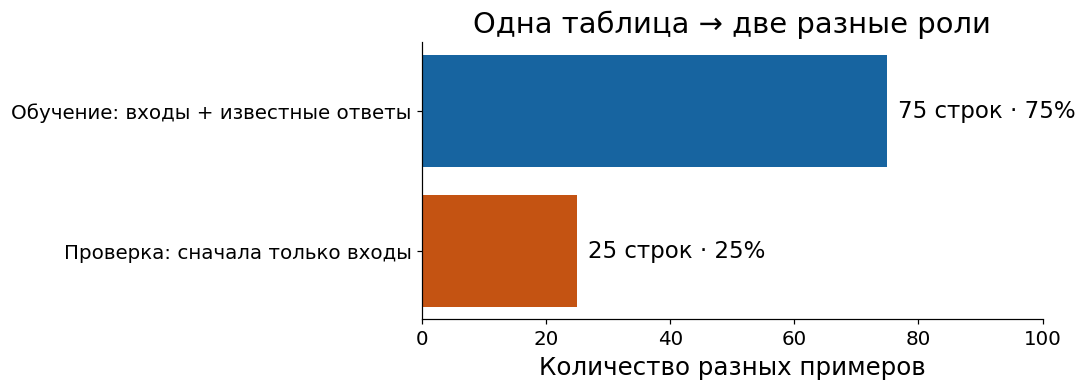

In [8]:
fig,ax=plt.subplots(figsize=(10,3.8))
bars=ax.barh(['Обучение: входы + известные ответы','Проверка: сначала только входы'],
             [len(exam_train),len(exam_valid)],color=[BLUE,ORANGE])
ax.bar_label(bars,labels=[f'{len(exam_train)} строк · 75%',f'{len(exam_valid)} строк · 25%'],padding=7,fontsize=15)
ax.set(xlim=(0,len(exam_data)),xlabel='Количество разных примеров',title='Одна таблица → две разные роли')
ax.invert_yaxis();plt.tight_layout();plt.show()

## К4. X — что известно, y — какой ответ хотим получить

Сначала используем **только процент принятых ДЗ**.

- `X` — входная таблица: у каждого примера одно число — принятые ДЗ;
- `y` — известный результат того же примера: 0 или 1.

Обе таблицы сохраняют порядок строк. Результат не может быть входом собственной задачи: если передать модели `Экзамен сдан` как признак, мы заранее подскажем ответ.

**Что делает следующая ячейка.** Выбирает вход и ответ из одних и тех же обучающих строк. Список `exam_feature_one` и двойные скобки сохраняют двумерную таблицу одного столбца — такой формат ожидает scikit-learn.

In [9]:
exam_feature_one=['Принятые ДЗ, %']
X_exam_one_train=exam_train[exam_feature_one]
y_exam_train=exam_train[exam_target]
X_exam_one_valid=exam_valid[exam_feature_one]
y_exam_valid=exam_valid[exam_target]
print('Один вход каждого обучающего примера:')
display(X_exam_one_train.head(5))
print('Его известный ответ в том же порядке:')
display(y_exam_train.head(5).to_frame('0 — не сдал; 1 — сдал'))

Один вход каждого обучающего примера:


,"Принятые ДЗ, %"
15,84
40,63
96,81
9,83
72,1


Его известный ответ в том же порядке:


,0 — не сдал; 1 — сдал
15,1
40,1
96,1
9,1
72,0


## К5. Начнём с правила, выбранного человеком

Для иллюстрации предложим грубое правило: **если принято больше 40% ДЗ, предскажем «сдал», иначе — «не сдал»**. Это пробная граница, а не правило зачёта и не вывод из данных.

На рисунке по X будет процент принятых ДЗ, по Y — известная категория. Точки над одним Y могут перекрываться: разные примеры способны иметь одинаковые проценты.

❓ Сколько известных результатов наше правило перепутает? Можно ли подобрать границу по обучающим примерам, а не на глаз?

**Что делает следующая ячейка.** Сравнение `>40` даёт True/False, а `astype(int)` превращает их в категории 1/0. Правило задано нами, fit здесь не вызывался. Пока смотрим обучающие примеры, чтобы понять саму задачу.

In [10]:
exam_manual_threshold=40.0
exam_manual_train=(exam_train['Принятые ДЗ, %']>exam_manual_threshold).astype(int)
manual_train_check=exam_train[['Номер','Принятые ДЗ, %',exam_target]].copy()
manual_train_check['Прогноз ручного правила']=exam_manual_train
display(manual_train_check.head(8))

,Номер,"Принятые ДЗ, %",Экзамен сдан,Прогноз ручного правила
15,16,84,1,1
40,41,63,1,1
96,97,81,1,1
9,10,83,1,1
72,73,1,0,0
11,12,58,0,1
47,48,41,1,1
85,86,10,1,0


**Что делает следующая ячейка.** Показывает известные категории и вертикальную ручную границу. Справа от линии ручное правило ответит 1, слева — 0. Реальные цвета точек позволяют заметить несовпадения.

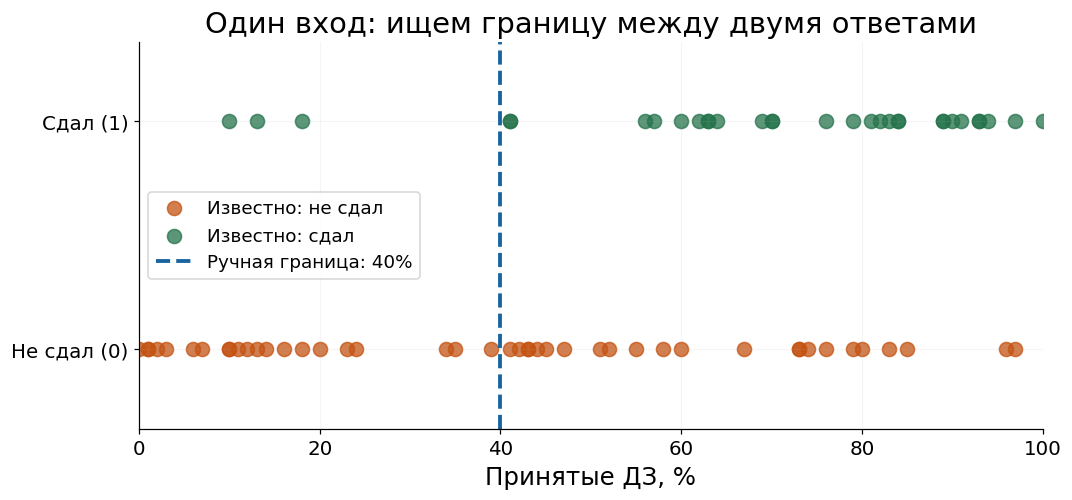

In [11]:
fig,ax=plt.subplots(figsize=(10,4.8))
for exam_class,color,label in [(0,ORANGE,'Известно: не сдал'),(1,GREEN,'Известно: сдал')]:
    group=exam_train.loc[exam_train[exam_target]==exam_class]
    ax.scatter(group['Принятые ДЗ, %'],group[exam_target],color=color,s=85,alpha=.75,label=label)
ax.axvline(exam_manual_threshold,color=BLUE,lw=2.5,linestyle='--',label='Ручная граница: 40%')
ax.set(xlim=(0,100),ylim=(-.35,1.35),xlabel='Принятые ДЗ, %',title='Один вход: ищем границу между двумя ответами')
ax.set_yticks([0,1],['Не сдал (0)','Сдал (1)'])
ax.legend(loc='center left');ax.grid(alpha=.12);plt.tight_layout();plt.show()

## 🟨❗ Почему одна граница лучше другой? Немного математики дерева

При выполнении условия «ДЗ не больше границы?» в одну группу попадут одни участники, при невыполнении — другие. Хотим, чтобы в получившихся группах **меньше смешивались разные ответы**.

Обозначим долю нулей в группе через `p0`, долю единиц — через `p1`. Число **Gini = 1 − p0² − p1²** измеряет смешанность двух категорий:

- все ответы одинаковые: `1 − 1² − 0² = 0`;
- половина 0, половина 1: `1 − 0,5² − 0,5² = 0,5`.

Меньше — однороднее. Для двух полученных групп берём среднее, **учитывая число участников**: большая группа имеет больший вес. Мы не пытаемся угадать ответы проверки: считаем только по обучению.

**Что делает следующая ячейка.** Функция `gini` считает доли двух категорий и подставляет их в формулу. `split_gini` разделяет только обучающие строки по границе и взвешивает смешанность групп по их размерам. `len` даёт размер группы, `mean` — долю ответов 1. Проверим формулу на трёх маленьких группах.

In [12]:
def gini(labels):
    if len(labels)==0:
        return 0.0
    p1=np.mean(labels)
    p0=1-p1
    return 1-p0**2-p1**2

def split_gini(threshold):
    left=exam_train.loc[exam_train['Принятые ДЗ, %']<=threshold,exam_target]
    right=exam_train.loc[exam_train['Принятые ДЗ, %']>threshold,exam_target]
    return (len(left)*gini(left)+len(right)*gini(right))/len(exam_train)

display(pd.DataFrame({'Группа':['Четыре нуля','Три нуля, одна единица','Два нуля, две единицы'],
                      'Gini':[gini([0,0,0,0]),gini([0,0,0,1]),gini([0,0,1,1])]}))

,Группа,Gini
0,Четыре нуля,0.000
1,"Три нуля, одна единица",0.375
2,"Два нуля, две единицы",0.500


**Что делает следующая ячейка.** Сортирует разные значения ДЗ в обучении и рассматривает границы посередине между соседними значениями. `unique` убирает повторы, `np.sort` упорядочивает числа. Для этого берём столбец прямо из обучающей таблицы `exam_train`. В конце `sort_values` упорядочивает строки таблицы сравнения по смешанности. Для каждой границы считаем смешанность; `idxmin` находит строку с наименьшим значением. Отдельно сравниваем её с ручной границей 40%.

In [13]:
values=np.sort(exam_train['Принятые ДЗ, %'].unique())
thresholds=(values[:-1]+values[1:])/2
gini_scores=pd.DataFrame({'Граница ДЗ, %':thresholds,
                          'Смешанность после разделения':[split_gini(t) for t in thresholds]})
best_row=gini_scores.loc[gini_scores['Смешанность после разделения'].idxmin()]
best_threshold=float(best_row['Граница ДЗ, %'])
display(gini_scores.sort_values('Смешанность после разделения').head(5))
display(pd.DataFrame({'Правило':['Ручная граница','Лучшее разделение обучения'],
                      'Граница':[exam_manual_threshold,best_threshold],
                      'Смешанность':[split_gini(exam_manual_threshold),split_gini(best_threshold)]}))

,"Граница ДЗ, %",Смешанность после разделения
27,55.5,0.346
26,53.5,0.357
28,56.5,0.362
30,59.0,0.366
25,51.5,0.367


,Правило,Граница,Смешанность
0,Ручная граница,40.0,0.407
1,Лучшее разделение обучения,55.5,0.346


**Что делает следующая ячейка.** Слева для каждой границы показывает Gini — насколько перемешаны разные ответы после разделения. Ниже — группы однороднее. Справа показывает число сдавших и не сдавших в двух группах для ручной и найденной границ. Два цвета в одной полосе означают, что в группе есть разные исходы.

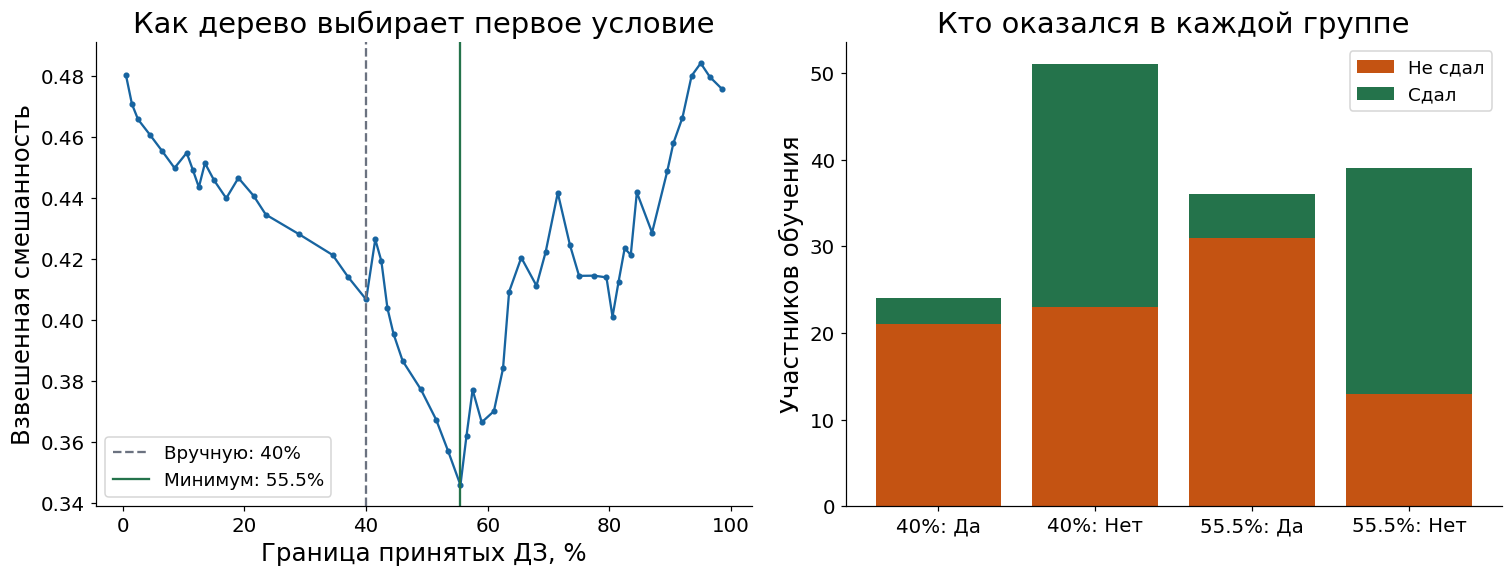

In [14]:
fig,axes=plt.subplots(1,2,figsize=(14,5.5))
axes[0].plot(gini_scores['Граница ДЗ, %'],gini_scores['Смешанность после разделения'],color=BLUE,marker='.')
axes[0].axvline(exam_manual_threshold,color=GRAY,ls='--',label='Вручную: 40%')
axes[0].axvline(best_threshold,color=GREEN,label=f'Минимум: {best_threshold:g}%')
axes[0].set(xlabel='Граница принятых ДЗ, %',ylabel='Взвешенная смешанность',title='Как дерево выбирает первое условие')
axes[0].legend()
labels=[];zeros=[];ones=[]
for threshold,title in [(exam_manual_threshold,'40%'),(best_threshold,f'{best_threshold:g}%')]:
    for mask,side in [(exam_train['Принятые ДЗ, %']<=threshold,'Да'),(exam_train['Принятые ДЗ, %']>threshold,'Нет')]:
        group=exam_train.loc[mask,exam_target]
        labels.append(f'{title}: {side}');zeros.append(int((group==0).sum()));ones.append(int((group==1).sum()))
axes[1].bar(labels,zeros,color=ORANGE,label='Не сдал')
axes[1].bar(labels,ones,bottom=zeros,color=GREEN,label='Сдал')
axes[1].set(ylabel='Участников обучения',title='Кто оказался в каждой группе')
axes[1].legend();plt.tight_layout();plt.show()

**Что мы нашли:** первое условие, который лучше разделяет **эти обучающие примеры** по выбранному числу Gini. Это ещё не оценка точности на новых участниках.

Внутри каждой ветки дерево может повторить поиск. Оно выбирает лучшее следующее условие в текущей группе, а не перебирает все возможные деревья целиком. Глубина ограничивает длину пути. В конечной группе прогноз — категория большинства. Разобранный пример использует числовые входы без пропусков.

## К6. Fit у дерева: подбери признак и границу по примерам

Для начала разрешим дереву **одно условие**: `max_depth=1`. Оно само выберет границу процента ДЗ, которая разделяет обучающие категории более однородно.

**У дерева fit подбирает условия, числовые границы и категорию в конце каждой ветки.** Готовое правило ему не передаём.

**Что делает следующая ячейка.** Создаёт дерево с одним условием и обучает его на 75 примерах. Строка чтения `tree_.threshold[0]` нужна только для показа найденной границы первого условия; значение не задаёт её вручную. Последние print показывают результат понятными словами, без карточки объекта.

In [15]:
exam_model_one=DecisionTreeClassifier(max_depth=1,random_state=42)
exam_model_one.fit(X_exam_one_train,y_exam_train)
exam_learned_threshold=float(exam_model_one.tree_.threshold[0])
print('Обучение по одному входу завершено.')
print('Модель нашла границу ДЗ:',exam_learned_threshold,'%')
print('Ручная граница была:',exam_manual_threshold,'%')

Обучение по одному входу завершено.
Модель нашла границу ДЗ: 55.5 %
Ручная граница была: 40.0 %


**Что делает следующая ячейка.** Добавляет найденную границу к той же картинке обучающих примеров. Модель изменила правило. Это ещё не доказательство качества на новых примерах: проверка будет отдельно.

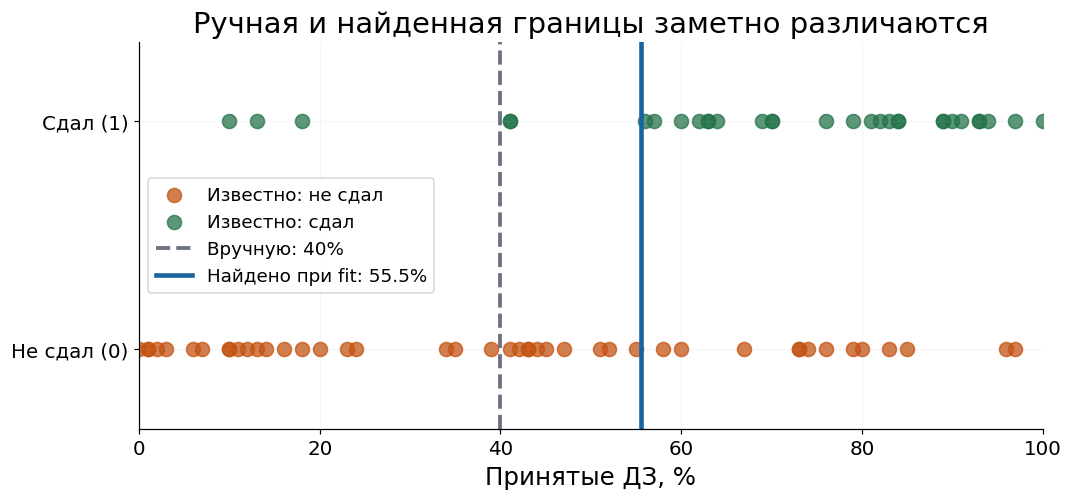

In [16]:
fig,ax=plt.subplots(figsize=(10,4.8))
for exam_class,color,label in [(0,ORANGE,'Известно: не сдал'),(1,GREEN,'Известно: сдал')]:
    group=exam_train.loc[exam_train[exam_target]==exam_class]
    ax.scatter(group['Принятые ДЗ, %'],group[exam_target],color=color,s=85,alpha=.75,label=label)
ax.axvline(exam_manual_threshold,color=GRAY,lw=2.5,linestyle='--',label=f'Вручную: {exam_manual_threshold:g}%')
ax.axvline(exam_learned_threshold,color=BLUE,lw=3,label=f'Найдено при fit: {exam_learned_threshold:g}%')
ax.set(xlim=(0,100),ylim=(-.35,1.35),xlabel='Принятые ДЗ, %',title='Ручная и найденная границы заметно различаются')
ax.set_yticks([0,1],['Не сдал (0)','Сдал (1)'])
ax.legend(loc='center left');ax.grid(alpha=.12);plt.tight_layout();plt.show()

## К7. Даём два входа и разбираем строку создания модели

Теперь разрешим использовать **посещаемость и принятые ДЗ**. Для каждого примера известны два числа. Это два столбца одного объекта, а не две категории результата.

Разберём команду `exam_model = DecisionTreeClassifier(max_depth=2, random_state=42)`:

| Фрагмент | Простое объяснение |
|---|---|
| `exam_model` | Имя переменной, в которой будем хранить модель |
| `=` | Сохрани созданный объект под этим именем |
| `DecisionTreeClassifier` | Создай дерево для выбора категории |
| `(...)` | Здесь передаём настройки инструмента |
| `max_depth=2` | На пути к одному ответу разрешено **не больше двух последовательных проверок условий** |
| `random_state=42` | Зафиксируй повторяемость внутренних случайных действий инструмента |

**Глубина 2 — не два признака и не две категории.** Категории 0/1 определяются ответами y. Доступные признаки определяются столбцами X. Глубина ограничивает длину пути условий.

Признаки и границы условий ещё не выбраны. `max_depth` — наша настройка сложности, а не результат обучения. Число 42 тоже не говорит о точности и не означает 42 примера.

**Что делает следующая ячейка.** Создаёт объект с заданными настройками и готовит два входных столбца. В этой ячейке нет fit, поэтому модель ещё не знает условий и не умеет давать обученные прогнозы.

In [17]:
X_exam_train=exam_train[exam_features]
X_exam_valid=exam_valid[exam_features]
exam_model=DecisionTreeClassifier(max_depth=2,random_state=42)
print('Создано дерево для категорий 0 и 1.')
print('Разрешено до двух условий на пути к ответу.')
print('Входные столбцы:',exam_features)
print('Обучение ещё не выполняли: теперь нужно вызвать fit.')
display(X_exam_train.head(4))

Создано дерево для категорий 0 и 1.
Разрешено до двух условий на пути к ответу.
Входные столбцы: ['Посещаемость, %', 'Принятые ДЗ, %']
Обучение ещё не выполняли: теперь нужно вызвать fit.


,"Посещаемость, %","Принятые ДЗ, %"
15,82,84
40,68,63
96,92,81
9,75,83


### Теперь вызываем fit отдельно

`exam_model.fit(X_exam_train, y_exam_train)` означает: **«Вот характеристики обучающих примеров и их известные результаты. Подбери условия дерева, которые помогают различать 0 и 1»**.

Участвуют только 75 обучающих строк. Ни признаки, ни ответы 25 проверочных строк в эту команду не передаём.

**Что делает следующая ячейка.** Fit подбирает дерево. `get_depth()` сообщает фактическое число уровней условий, которое получилось. Последняя команда print заменяет автоматическую карточку объекта понятным сообщением. Здесь нет ни прогноза, ни процента точности.

In [18]:
exam_model.fit(X_exam_train,y_exam_train)
tree_info=exam_model.tree_
print('Обучение завершено.')
print('Использовано обучающих примеров:',len(X_exam_train))
print('Доступных признаков:',X_exam_train.shape[1])
print('Фактическая глубина найденного дерева:',exam_model.get_depth())
print('Качество ещё не проверяли: дальше применим модель к отложенным строкам.')

Обучение завершено.
Использовано обучающих примеров: 75
Доступных признаков: 2
Фактическая глубина найденного дерева: 2
Качество ещё не проверяли: дальше применим модель к отложенным строкам.


### Что означала синяя карточка DecisionTreeClassifier?

В Jupyter результат последнего выражения ячейки показывается автоматически. Метод `fit` возвращает **сам объект модели**, поэтому строка с fit в конце ячейки может вывести справочную карточку.

- **Parameters** — настройки, переданные при создании, например `max_depth`.
- **Fitted attributes** — сведения, появившиеся после обучения: найденное дерево, число входов и другие атрибуты.

**Карточка — не прогноз, не таблица ошибок и не подтверждение хорошего качества.** В наших ячейках вместо неё будут понятные подписи и рисунок найденного дерева.

## К8. 👁 Посмотрим на условия, которые действительно нашла модель

Начинаем с верхнего условия. Если условие выполняется, идём по ветке **«Да»**; иначе — **«Нет»**. В конечном прямоугольнике записан прогноз категории.

Не требуется пройти два условия на каждой ветке: `max_depth=2` означает «не больше двух». В некоторых ветках ответ находится раньше.

**Что делает следующая ячейка.** Вспомогательный код читает найденную структуру дерева и рисует обычную схему условий и ответов. Он не создаёт новые правила и не переобучает модель. Цветные конечные блоки показывают категории, а не метрики качества.

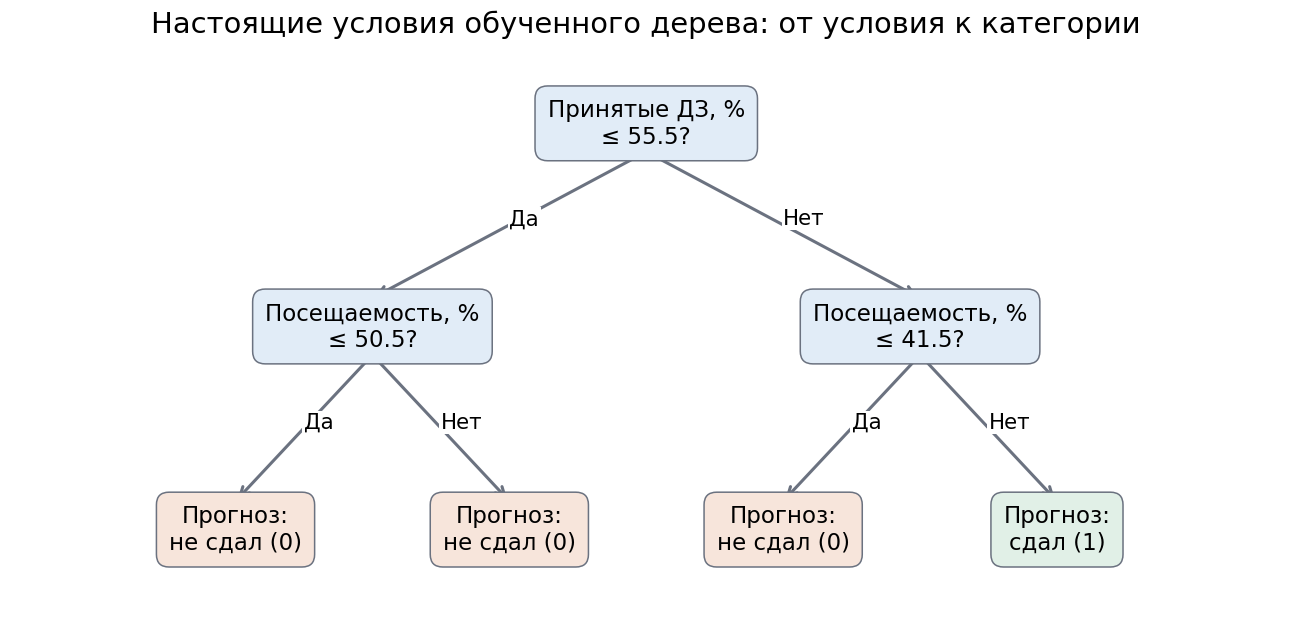

In [19]:
tree_info=exam_model.tree_
node_positions={}
def place_node(node,x,y,gap):
    node_positions[node]=(x,y)
    if tree_info.children_left[node]!=tree_info.children_right[node]:
        place_node(tree_info.children_left[node],x-gap,y-1,gap/2)
        place_node(tree_info.children_right[node],x+gap,y-1,gap/2)
place_node(0,0.5,2,0.25)
fig,ax=plt.subplots(figsize=(12,6))
for node,(x,y) in node_positions.items():
    is_leaf=tree_info.children_left[node]==tree_info.children_right[node]
    if is_leaf:
        predicted=int(exam_model.classes_[np.argmax(tree_info.value[node][0])])
        text='Прогноз:'+chr(10)+('сдал (1)' if predicted==1 else 'не сдал (0)')
        face='#e1f0e7' if predicted==1 else '#f7e5db'
    else:
        feature=exam_features[tree_info.feature[node]]
        text=feature+'\n≤ '+f'{tree_info.threshold[node]:g}'+'?'
        face='#e1ecf7'
        for child,answer in [(tree_info.children_left[node],'Да'),(tree_info.children_right[node],'Нет')]:
            cx,cy=node_positions[child]
            ax.annotate('',xy=(cx,cy+.14),xytext=(x,y-.14),
                        arrowprops={'arrowstyle':'->','color':GRAY,'lw':2})
            ax.text((x+cx)/2,(y+cy)/2,answer,fontsize=14,
                    bbox={'facecolor':'white','edgecolor':'none','pad':1})
    ax.text(x,y,text,ha='center',va='center',fontsize=15,
            bbox={'boxstyle':'round,pad=.55','facecolor':face,'edgecolor':GRAY})
ax.set(xlim=(-.08,1.08),ylim=(-.45,2.4),title='Настоящие условия обученного дерева: от условия к категории')
ax.axis('off');plt.tight_layout();plt.show()

На схеме дерево использует **и принятые ДЗ, и посещаемость**. При обучении ему были доступны оба столбца; для каждой группы оно выбрало полезное условие отдельно.

На новом примере идём по одной ветке на каждом шаге. Условие из другой ветки не проверяем. Несколько конечных блоков могут давать одну категорию — это допустимо. Большая глубина не гарантирует лучшее качество.

## К9. Пройдём один пример по дереву вручную

Известны 80% посещений и 70% принятых ДЗ. До запуска попробуйте пройти по рисунку от верхнего условия до конечного ответа.

Служебная ячейка ниже запишет путь словами. Затем сравним этот путь с `predict`.

**Что делает следующая ячейка.** Подставляет значения одной новой строки в условия уже обученного дерева. Выбор ветки зависит от ответа «Да/Нет». В конце читает категорию конечного блока. Это объяснение готового правила, а не дополнительное обучение.

In [20]:
exam_new=pd.DataFrame({'Посещаемость, %':[80.0],'Принятые ДЗ, %':[70.0]})
node=0
trace_steps=[]
while tree_info.children_left[node]!=tree_info.children_right[node]:
    feature=exam_features[tree_info.feature[node]]
    threshold=float(tree_info.threshold[node])
    value=float(exam_new.iloc[0][feature])
    answer=value<=threshold
    trace_steps.append(f'{feature}: {value:g} ≤ {threshold:g}? '+('Да' if answer else 'Нет'))
    node=tree_info.children_left[node] if answer else tree_info.children_right[node]
exam_trace_class=int(exam_model.classes_[np.argmax(tree_info.value[node][0])])
for step in trace_steps:print(step)
print('В конце пути:', 'сдал (1)' if exam_trace_class==1 else 'не сдал (0)')

Принятые ДЗ, %: 70 ≤ 55.5? Нет
Посещаемость, %: 80 ≤ 41.5? Нет
В конце пути: сдал (1)


### Predict — короткий способ применить те же условия

**Что делает следующая ячейка.** Проверяет, что чтение схемы и вызов predict дают одну категорию. `[0]` выбирает первый ответ из массива, потому что строка новой заявки одна.

In [21]:
exam_new_class=int(exam_model.predict(exam_new)[0])
display(exam_new)
print('Ответ predict:', 'сдал (1)' if exam_new_class==1 else 'не сдал (0)')
print('Совпадает с пройденным по схеме путём:',exam_new_class==exam_trace_class)

,"Посещаемость, %","Принятые ДЗ, %"
0,80.0,70.0


Ответ predict: сдал (1)
Совпадает с пройденным по схеме путём: True


## К10. Теперь проверим на 25 других примерах

Новая заявка не дала оценки качества: её настоящего исхода у нас нет. Для проверки используем отложенные примеры, где исход известен нам, но не использовался при fit.

Получим три набора ответов: ручное правило, дерево с одним входом и дерево с двумя доступными входами. Все способы проверяются **на одних и тех же 25 строках**.

**Что делает следующая ячейка.** Передаёт каждой готовой модели только её входы проверочных строк. Затем ставит прогнозы рядом с настоящими категориями. Столбец True/False показывает совпадение двухвходной модели с известным результатом.

In [22]:
exam_predictions=exam_model.predict(X_exam_valid)
exam_one_predictions=exam_model_one.predict(X_exam_one_valid)
exam_manual_predictions=(exam_valid['Принятые ДЗ, %']>exam_manual_threshold).astype(int).to_numpy()
exam_check=exam_valid[['Номер']+exam_features+[exam_target]].copy()
exam_check['Ручное правило']=exam_manual_predictions
exam_check['Прогноз по одному входу']=exam_one_predictions
exam_check['Прогноз модели']=exam_predictions
exam_check['Ответ верный']=exam_check['Прогноз модели']==exam_check[exam_target]
display(exam_check)

,Номер,"Посещаемость, %","Принятые ДЗ, %",Экзамен сдан,Ручное правило,Прогноз по одному входу,Прогноз модели,Ответ верный
83,84,57,63,1,1,1,1,True
53,54,27,39,0,0,0,0,True
70,71,23,67,0,1,1,0,True
45,46,61,27,0,0,0,0,True
44,45,14,20,0,0,0,0,True
39,40,17,40,0,0,0,0,True
22,23,10,16,0,0,0,0,True
80,81,25,9,0,0,0,0,True
10,11,70,88,1,1,1,1,True
0,1,79,88,1,1,1,1,True


## К11. Accuracy: какая доля ответов верна?

Если из 25 ответов верны 21, accuracy = 21/25 = 0,84 = **84%**. Это доля совпадений в этой проверке, а не вероятность сдачи отдельного участника.

`accuracy_score(y_exam_valid, exam_predictions)` сравнивает настоящие и предсказанные категории в одинаковом порядке. Для ориентира также дадим всем самый частый ответ **обучающей** части.

Ручное правило тоже может работать хорошо. Разница в том, что его границу предложил человек, а дерево выбрало границы по обучению. Качество любого способа всё равно проверяем на других участниках. Равная accuracy не означает одинаковые прогнозы или одинаковые ошибки.

**Что делает следующая ячейка.** Сравнивает четыре способа на одних 25 участниках и показывает число верных ответов. Затем ищет различия между ручным правилом и деревом по одному входу. На этой проверке их ответы совпали, поэтому таблица различий пуста. Ниже показывает примеры обучения, где разные границы всё-таки дают разные ответы. Эти знакомые примеры объясняют различие правил, но не заменяют проверку качества на других людях.

In [23]:
exam_baseline_class=y_exam_train.mode().iloc[0]
exam_baseline_predictions=np.full(len(exam_valid),exam_baseline_class)
exam_baseline_accuracy=accuracy_score(y_exam_valid,exam_baseline_predictions)
exam_accuracy=accuracy_score(y_exam_valid,exam_predictions)
exam_correct=int((exam_predictions==y_exam_valid.to_numpy()).sum())
exam_scores=pd.DataFrame({
    'Способ':['Всем частую категорию','Ручная граница 40%','Дерево: один вход','Дерево: два доступных входа'],
    f'Верных из {len(exam_valid)}':[
        int((exam_baseline_predictions==y_exam_valid.to_numpy()).sum()),
        int((exam_manual_predictions==y_exam_valid.to_numpy()).sum()),
        int((exam_one_predictions==y_exam_valid.to_numpy()).sum()),exam_correct],
    'Accuracy, %':[
        exam_baseline_accuracy*100,
        accuracy_score(y_exam_valid,exam_manual_predictions)*100,
        accuracy_score(y_exam_valid,exam_one_predictions)*100,exam_accuracy*100]
})
display(exam_scores)
print(f'У модели {exam_correct} верных ответов из {len(exam_valid)}: {exam_accuracy:.0%}.')
print('Ручная проверка среднего True/False:',exam_check['Ответ верный'].mean())

manual_one_check=exam_check[['Номер']+exam_features+[exam_target,'Ручное правило','Прогноз по одному входу']].copy()
manual_one_check['Ручное верно']=manual_one_check['Ручное правило']==manual_one_check[exam_target]
manual_one_check['Дерево верно']=manual_one_check['Прогноз по одному входу']==manual_one_check[exam_target]
manual_one_disagreements=manual_one_check.loc[manual_one_check['Ручное правило']!=manual_one_check['Прогноз по одному входу']]
print('Ручное правило и дерево по одному входу ответили по-разному:')
display(manual_one_disagreements)
print('Различий в проверке:',len(manual_one_disagreements))
train_rule_check=exam_train[['Номер']+exam_features+[exam_target]].copy()
train_rule_check['Ручное правило']=exam_manual_train
train_rule_check['Дерево: один вход']=exam_model_one.predict(X_exam_one_train)
train_rule_disagreements=train_rule_check.loc[train_rule_check['Ручное правило']!=train_rule_check['Дерево: один вход']]
print('Примеры обучения, на которых границы дают разные ответы:')
display(train_rule_disagreements.head(6))
print('Здесь объясняем различие правил, а не оцениваем качество по обучению.')

,Способ,Верных из 25,"Accuracy, %"
0,Всем частую категорию,15,60.0
1,Ручная граница 40%,21,84.0
2,Дерево: один вход,21,84.0
3,Дерево: два доступных входа,24,96.0


У модели 24 верных ответов из 25: 96%.
Ручная проверка среднего True/False: 0.96
Ручное правило и дерево по одному входу ответили по-разному:


,Номер,"Посещаемость, %","Принятые ДЗ, %",Экзамен сдан,Ручное правило,Прогноз по одному входу,Ручное верно,Дерево верно


Различий в проверке: 0
Примеры обучения, на которых границы дают разные ответы:


,Номер,"Посещаемость, %","Принятые ДЗ, %",Экзамен сдан,Ручное правило,Дерево: один вход
47,48,64,41,1,1,0
81,82,84,42,0,1,0
17,18,75,45,0,1,0
64,65,93,41,0,1,0
67,68,93,44,0,1,0
61,62,32,43,0,1,0


Здесь объясняем различие правил, а не оцениваем качество по обучению.


## К12. Таблица ошибок: какие категории модель перепутала?

**Строки — настоящий исход, столбцы — прогноз.** На диагонали совпадения, вне диагонали ошибки. Числа — количество проверочных примеров.

`confusion_matrix(..., labels=[0,1])` считает четыре сочетания в порядке «не сдал», затем «сдал». Сначала прочитаем таблицу, затем покажем сами ошибочные примеры.

**Что делает следующая ячейка.** После таблицы переводит каждую её ячейку в обычное предложение. Все ошибки показываются отдельными строками. Такая проверка содержательнее, чем одна карточка модели или одно число accuracy.

In [24]:
exam_confusion=confusion_matrix(y_exam_valid,exam_predictions,labels=[0,1])
display(pd.DataFrame(exam_confusion,index=['Факт: не сдал','Факт: сдал'],
                     columns=['Прогноз: не сдал','Прогноз: сдал']))
print('Правильно предсказал «не сдал»:',exam_confusion[0,0])
print('Ошибочно обещал «сдал»:',exam_confusion[0,1])
print('Ошибочно предсказал «не сдал»:',exam_confusion[1,0])
print('Правильно предсказал «сдал»:',exam_confusion[1,1])
display(exam_check.loc[~exam_check['Ответ верный']])

,Прогноз: не сдал,Прогноз: сдал
Факт: не сдал,15,0
Факт: сдал,1,9


Правильно предсказал «не сдал»: 15
Ошибочно обещал «сдал»: 0
Ошибочно предсказал «не сдал»: 1
Правильно предсказал «сдал»: 9


,Номер,"Посещаемость, %","Принятые ДЗ, %",Экзамен сдан,Ручное правило,Прогноз по одному входу,Прогноз модели,Ответ верный
55,56,48,19,1,0,0,0,False


## К13. 👁 Три способа на одних проверочных участниках

Слева ручное условие по ДЗ, в центре обученное условие по ДЗ, справа дерево с доступом к ДЗ и посещаемости. У всех одинаковые 25 проверочных участников и одинаковые оси.

По X — посещаемость, по Y — принятые ДЗ. Цвет фона — прогноз способа, цвет точки — настоящий исход, чёрный крест — ошибка. Горизонтальная граница использует только ДЗ; вертикальные отрезки справа показывают, где понадобилась посещаемость.

**Что делает следующая ячейка.** На одной сетке рисует ручную границу и прогнозы двух деревьев. Для каждого способа подписывает число верных ответов и выделяет его собственные ошибки на тех же 25 примерах. Сетка нужна только для картинки и не участвует в обучении.

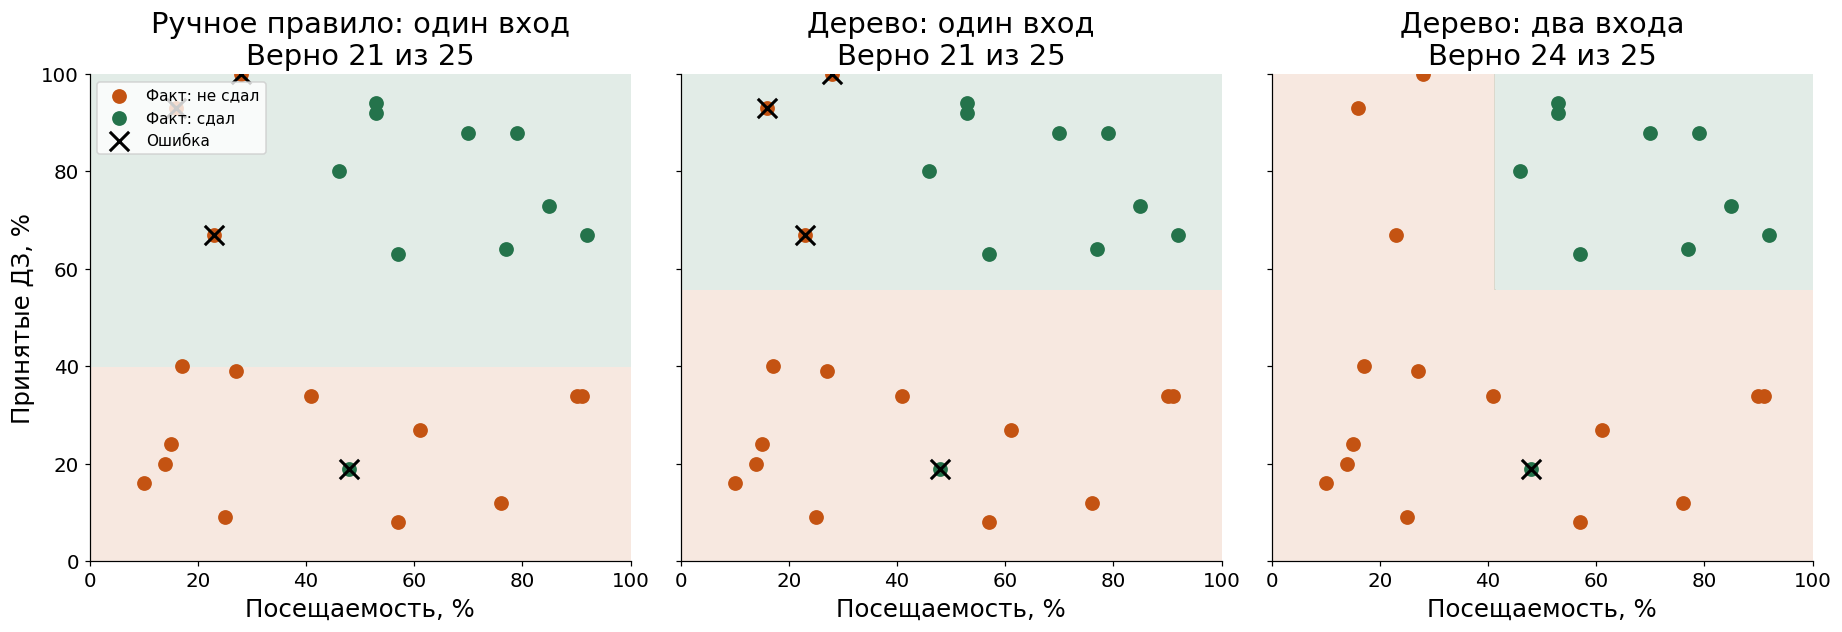

In [25]:
grid_attendance,grid_homework=np.meshgrid(np.linspace(0,100,160),np.linspace(0,100,160))
exam_grid=pd.DataFrame({exam_features[0]:grid_attendance.ravel(),exam_features[1]:grid_homework.ravel()})
manual_background=(exam_grid['Принятые ДЗ, %']>exam_manual_threshold).astype(int).to_numpy()
one_background=exam_model_one.predict(exam_grid[exam_feature_one])
two_background=exam_model.predict(exam_grid)
fig,axes=plt.subplots(1,3,figsize=(17,6),sharex=True,sharey=True)
for ax,background,prediction,label in [
    (axes[0],manual_background,exam_manual_predictions,'Ручное правило: один вход'),
    (axes[1],one_background,exam_one_predictions,'Дерево: один вход'),
    (axes[2],two_background,exam_predictions,'Дерево: два входа')]:
    ax.contourf(grid_attendance,grid_homework,background.reshape(grid_attendance.shape),levels=[-.5,.5,1.5],colors=[ORANGE,GREEN],alpha=.13)
    for exam_class,color,title in [(0,ORANGE,'Факт: не сдал'),(1,GREEN,'Факт: сдал')]:
        group=exam_valid.loc[exam_valid[exam_target]==exam_class]
        ax.scatter(group[exam_features[0]],group[exam_features[1]],s=75,color=color,label=title)
    wrong=exam_valid.loc[prediction!=y_exam_valid.to_numpy()]
    ax.scatter(wrong[exam_features[0]],wrong[exam_features[1]],s=160,marker='x',color='black',lw=2,label='Ошибка')
    correct=int((prediction==y_exam_valid.to_numpy()).sum())
    ax.set(xlim=(0,100),ylim=(0,100),xlabel='Посещаемость, %',title=f'{label}\nВерно {correct} из {len(exam_valid)}')
axes[0].set_ylabel('Принятые ДЗ, %')
axes[0].legend(loc='upper left',fontsize=10)
plt.tight_layout();plt.show()

## К14. Другой способ: спросим ближайших соседей

Дерево последовательно проверяло условия. **Метод k ближайших соседей — kNN — действует иначе:** находит похожие обучающие примеры и выбирает категорию большинством их голосов.

Возьмём ещё одну новую заявку: **60% посещений, 60% принятых ДЗ**. Настоящий итог неизвестен. На графике это точка (60, 60).

Выберем **k = 5**: голосуют пять ближайших обучающих примеров. Число 5 задаём заранее для демонстрации, а не подбираем по ответам проверочных строк.

Соседство — близость **двух характеристик**, а не номеров строк или фамилий. До результата нового примера расстояние измерить нельзя: его результата ещё нет.

**Что делает следующая ячейка.** Задаёт новую пару входов и напоминает, где ищем соседей. Проверочные примеры и их результаты для поиска не используем.

In [26]:
knn_query=pd.DataFrame({'Посещаемость, %':[60.0],'Принятые ДЗ, %':[60.0]})
display(knn_query)
print('Будем искать пять похожих примеров только среди',len(exam_train),'обучающих строк.')

,"Посещаемость, %","Принятые ДЗ, %"
0,60.0,60.0


Будем искать пять похожих примеров только среди 75 обучающих строк.


### Посчитаем близость без скрытой команды

У каждого обучающего примера найдём два отличия от заявки: по посещаемости и по ДЗ. Расстояние — обычная длина отрезка между точками:

**корень из (разница посещаемости² + разница ДЗ²)**.

Например, от точки (60,60) до (63,64) расстояние равно √(3²+4²)=5. Небольшие отличия по обеим характеристикам означают близкого соседа.

Оба наших входа измерены в процентах 0–100, и в этом примере даём им одинаковый вес. При разных единицах, например «возраст» и «доход», сначала понадобилось бы согласовать масштабы, иначе большие числа могут определять почти всё расстояние.

**Что делает следующая ячейка.** Вычисляет расстояние до каждого обучающего примера, сортирует от меньшего к большему и берёт первые пять. Таблица показывает и входы соседей, и их известные исходы. Соседей выбирает расстояние, а не их ответы.

In [27]:
knn_attendance_difference=exam_train['Посещаемость, %']-knn_query.iloc[0]['Посещаемость, %']
knn_homework_difference=exam_train['Принятые ДЗ, %']-knn_query.iloc[0]['Принятые ДЗ, %']
knn_manual_distances=np.sqrt(knn_attendance_difference**2+knn_homework_difference**2)
knn_neighbors=exam_train[['Номер']+exam_features+[exam_target]].copy()
knn_neighbors['Расстояние до заявки']=knn_manual_distances
knn_nearest=knn_neighbors.sort_values('Расстояние до заявки').head(5)
display(knn_nearest)

,Номер,"Посещаемость, %","Принятые ДЗ, %",Экзамен сдан,Расстояние до заявки
54,55,65,64,1,6.403
40,41,68,63,1,8.544
20,21,63,51,0,9.487
84,85,67,52,0,10.630
87,88,73,63,1,13.342


**Что делает следующая ячейка.** Показывает ту же новую точку, всех обучающих соседей и выделенные пять ближайших. Пунктир показывает расстояния, цифры — порядок близости. Голосуют только точки в синих кольцах.

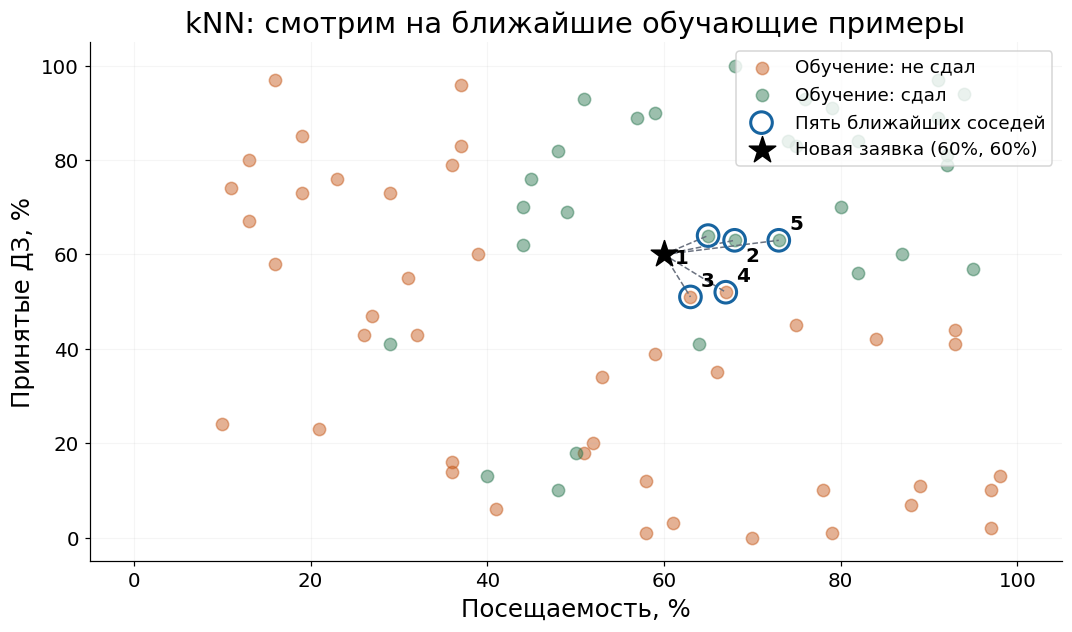

In [28]:
fig,ax=plt.subplots(figsize=(10,6))
for exam_class,color,label in [(0,ORANGE,'Обучение: не сдал'),(1,GREEN,'Обучение: сдал')]:
    group=exam_train.loc[exam_train[exam_target]==exam_class]
    ax.scatter(group[exam_features[0]],group[exam_features[1]],s=65,color=color,alpha=.45,label=label)
for rank,(_,row) in enumerate(knn_nearest.iterrows(),start=1):
    ax.plot([60,row[exam_features[0]]],[60,row[exam_features[1]]],color=GRAY,linestyle='--',lw=1)
    label_offset=(-22,-18) if rank==1 else ((7,-14) if rank==2 else (7,7))
    ax.annotate(str(rank),xy=(row[exam_features[0]],row[exam_features[1]]),xytext=label_offset,
                textcoords='offset points',fontsize=13,fontweight='bold')
ax.scatter(knn_nearest[exam_features[0]],knn_nearest[exam_features[1]],s=200,
           facecolors='none',edgecolors=BLUE,linewidths=2,label='Пять ближайших соседей',zorder=4)
ax.scatter([60],[60],s=330,marker='*',color='black',label='Новая заявка (60%, 60%)',zorder=5)
ax.set(xlim=(-5,105),ylim=(-5,105),xlabel='Посещаемость, %',ylabel='Принятые ДЗ, %',
       title='kNN: смотрим на ближайшие обучающие примеры')
ax.legend(loc='upper right');ax.grid(alpha=.12);plt.tight_layout();plt.show()

### Пять соседей голосуют

У каждого соседа один голос — его известный исход. В таблице выше три ближайших участника сдали, два не сдали. Поэтому большинство предсказывает «сдал».

Это подсчёт голосов пяти **обучающих** примеров. Настоящий исход новой заявки по-прежнему неизвестен. Ручной подсчёт здесь повторяет алгоритм kNN — это другая ручная работа, чем наша первоначальная граница 40%.

**Что делает следующая ячейка.** Считает голоса пяти выбранных соседей. `value_counts()` считает категории, `reindex([0,1])` сохраняет понятный порядок, `idxmax()` находит категорию с наибольшим числом голосов.

In [29]:
knn_votes=knn_nearest[exam_target].value_counts().reindex([0,1],fill_value=0)
knn_manual_class=int(knn_votes.idxmax())
display(pd.DataFrame({'Категория':['Не сдал (0)','Сдал (1)'],'Голосов':knn_votes.to_numpy()}))
print('Ответ большинства:', 'сдал (1)' if knn_manual_class==1 else 'не сдал (0)')

,Категория,Голосов
0,Не сдал (0),2
1,Сдал (1),3


Ответ большинства: сдал (1)


## К15. Та же работа готовым инструментом KNeighborsClassifier

`KNeighborsClassifier(n_neighbors=5)` создаёт классификатор, который ищет пять соседей. С настройками по умолчанию расстояние — обычное геометрическое, все пять голосов равны.

**Fit у kNN** сохраняет обучающие входы и ответы для дальнейшего поиска соседей. Он не ищет прямую и не строит условия дерева. **Predict** ищет ближайшие примеры к новой строке и возвращает категорию по голосам.

**Что делает следующая ячейка.** Подключает и создаёт kNN с пятью соседями. Fit получает те же два входа и те же известные обучающие категории, что дерево. Заканчиваем понятным сообщением, а не служебной карточкой объекта.

In [30]:
from sklearn.neighbors import KNeighborsClassifier
knn_model=KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_exam_train,y_exam_train)
print('kNN подготовлен: использованы только обучающие примеры.')
print('Соседей для каждой заявки:',knn_model.n_neighbors)

kNN подготовлен: использованы только обучающие примеры.
Соседей для каждой заявки: 5


**Что делает следующая ячейка.** Подтверждает, что библиотека воспроизвела ручной выбор большинства. Дерево может ответить иначе на те же входы, потому что использует другой способ. По одной заявке без настоящего результата нельзя решить, кто прав.

In [31]:
knn_query_class=int(knn_model.predict(knn_query)[0])
tree_query_class=int(exam_model.predict(knn_query)[0])
print('Наш ручной подсчёт соседей:','сдал' if knn_manual_class==1 else 'не сдал')
print('Готовая функция kNN:','сдал' if knn_query_class==1 else 'не сдал')
print('Дерево на той же заявке:','сдал' if tree_query_class==1 else 'не сдал')
print('Ручные голоса и kNN совпали:',knn_query_class==knn_manual_class)

Наш ручной подсчёт соседей: сдал
Готовая функция kNN: сдал
Дерево на той же заявке: сдал
Ручные голоса и kNN совпали: True


## К16. Сравним дерево и kNN на одинаковых 25 примерах

Оба метода используют **те же 75 строк обучения и те же 25 строк проверки**. Никаких новых правильных ответов одному из них не подсказываем.

Сначала покажем ответы обоих методов по строкам, затем посчитаем accuracy и ошибки каждого. `k=5` и глубина дерева 2 заданы заранее для этого сравнения.

**Что делает следующая ячейка.** Не меняет обучение и проверку: получает ответы kNN на тех же 25 участниках и сравнивает с деревом. В этой версии дерево верно ответило 24 раза, kNN — 25 раз. Полное совпадение на 25 примерах — результат этого опыта, а не гарантия безошибочности метода.

In [32]:
knn_predictions=knn_model.predict(X_exam_valid)
knn_accuracy=accuracy_score(y_exam_valid,knn_predictions)
classifier_check=exam_valid[['Номер']+exam_features+[exam_target]].copy()
classifier_check['Дерево']=exam_predictions
classifier_check['kNN, k=5']=knn_predictions
classifier_check['Дерево верно']=classifier_check['Дерево']==classifier_check[exam_target]
classifier_check['kNN верно']=classifier_check['kNN, k=5']==classifier_check[exam_target]
display(classifier_check)
classifier_comparison=pd.DataFrame({
    'Метод':['Дерево, глубина до 2','kNN, пять соседей'],
    f'Верных из {len(exam_valid)}':[int(classifier_check['Дерево верно'].sum()),int(classifier_check['kNN верно'].sum())],
    'Accuracy, %':[exam_accuracy*100,knn_accuracy*100]
})
display(classifier_comparison)

,Номер,"Посещаемость, %","Принятые ДЗ, %",Экзамен сдан,Дерево,"kNN, k=5",Дерево верно,kNN верно
83,84,57,63,1,1,1,True,True
53,54,27,39,0,0,0,True,True
70,71,23,67,0,0,0,True,True
45,46,61,27,0,0,0,True,True
44,45,14,20,0,0,0,True,True
39,40,17,40,0,0,0,True,True
22,23,10,16,0,0,0,True,True
80,81,25,9,0,0,0,True,True
10,11,70,88,1,1,1,True,True
0,1,79,88,1,1,1,True,True


,Метод,Верных из 25,"Accuracy, %"
0,"Дерево, глубина до 2",24,96.0
1,"kNN, пять соседей",25,100.0


**Что делает следующая ячейка.** Сопоставляет виды ошибок, а не только проценты. Порядок строк и столбцов у обеих матриц одинаковый. Последняя таблица показывает конкретные примеры разногласий.

In [33]:
knn_confusion=confusion_matrix(y_exam_valid,knn_predictions,labels=[0,1])
print('Дерево:')
display(pd.DataFrame(exam_confusion,index=['Факт: не сдал','Факт: сдал'],
                     columns=['Прогноз: не сдал','Прогноз: сдал']))
print('kNN:')
display(pd.DataFrame(knn_confusion,index=['Факт: не сдал','Факт: сдал'],
                     columns=['Прогноз: не сдал','Прогноз: сдал']))
print('Строки, где методы ответили по-разному:')
display(classifier_check.loc[classifier_check['Дерево']!=classifier_check['kNN, k=5']])

Дерево:


,Прогноз: не сдал,Прогноз: сдал
Факт: не сдал,15,0
Факт: сдал,1,9


kNN:


,Прогноз: не сдал,Прогноз: сдал
Факт: не сдал,15,0
Факт: сдал,0,10


Строки, где методы ответили по-разному:


,Номер,"Посещаемость, %","Принятые ДЗ, %",Экзамен сдан,Дерево,"kNN, k=5",Дерево верно,kNN верно
55,56,48,19,1,0,1,False,True


## К17. 👁 Почему границы двух методов различаются?

Слева дерево разделяет пространство условиями вида «признак не больше границы?». Справа kNN выбирает большинство среди локальных соседей, поэтому границы могут быть более неровными.

На обеих картинках одинаковые масштабы и те же проверочные точки. Цвет фона — прогноз, цвет точки — истинная категория, чёрный крест — ошибка соответствующего метода.

**Что делает следующая ячейка.** Рисует прогнозы обоих уже обученных методов на общей сетке, а ошибки отмечает по одним и тем же отложенным примерам. Сетка нужна только для картинки, она не используется в обучении.

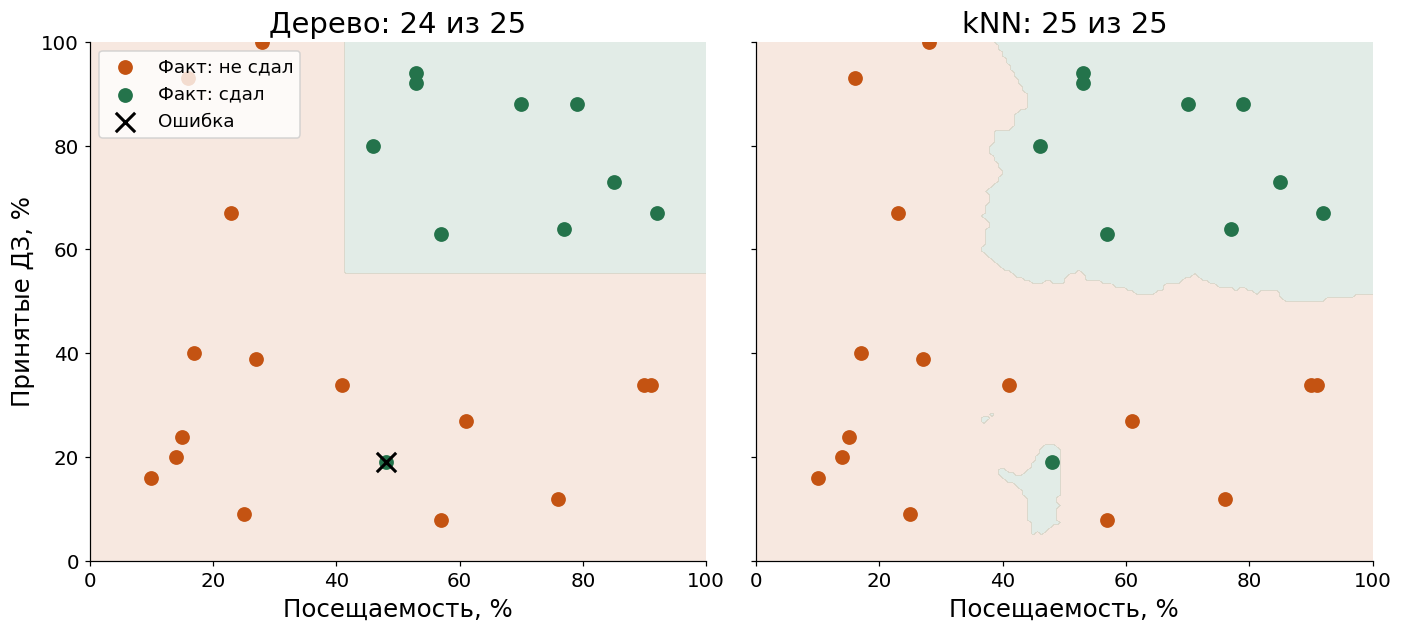

In [34]:
compare_x,compare_y=np.meshgrid(np.linspace(0,100,150),np.linspace(0,100,150))
compare_grid=pd.DataFrame({exam_features[0]:compare_x.ravel(),exam_features[1]:compare_y.ravel()})
fig,axes=plt.subplots(1,2,figsize=(13,6),sharex=True,sharey=True)
for ax,model,predictions,title in [
    (axes[0],exam_model,exam_predictions,f'Дерево: {exam_correct} из {len(exam_valid)}'),
    (axes[1],knn_model,knn_predictions,f'kNN: {int((knn_predictions==y_exam_valid.to_numpy()).sum())} из {len(exam_valid)}')]:
    background=model.predict(compare_grid).reshape(compare_x.shape)
    ax.contourf(compare_x,compare_y,background,levels=[-.5,.5,1.5],colors=[ORANGE,GREEN],alpha=.13)
    for exam_class,color,label in [(0,ORANGE,'Факт: не сдал'),(1,GREEN,'Факт: сдал')]:
        group=exam_valid.loc[exam_valid[exam_target]==exam_class]
        ax.scatter(group[exam_features[0]],group[exam_features[1]],s=75,color=color,label=label)
    errors=predictions!=y_exam_valid.to_numpy()
    wrong=exam_valid.loc[errors]
    ax.scatter(wrong[exam_features[0]],wrong[exam_features[1]],marker='x',s=160,color='black',lw=2,label='Ошибка')
    ax.set(xlim=(0,100),ylim=(0,100),xlabel='Посещаемость, %',title=title)
axes[0].set_ylabel('Принятые ДЗ, %')
axes[0].legend(loc='upper left');plt.tight_layout();plt.show()

### Что можно заключить?

- Ручная граница и дерево по одному входу дали по **21 из 25 (84%)**. На этих 25 людях совпали и сами ответы: между границами 40% и 55,5% не оказалось проверочных участников. На обучающих примерах выше видно, что правила всё-таки различаются.
- Дерево по двум входам дало **24 из 25 (96%)**: на этом примере сведения о посещаемости помогли различать случаи с похожими ДЗ.
- kNN дал **25 из 25 (100%)**. Проверка мала и данные вымышленные: это не обещание идеального качества на другой группе.
- Ручное правило тоже может быть полезным. Преимущество обучения — возможность систематически подобрать правило по многим известным примерам и нескольким входам. Улучшение качества надо проверить, оно не гарантировано названием модели.
- Если начнём выбирать настройки по этой проверке, для независимой итоговой оценки понадобится новая, ещё не использованная часть.

Одна ошибка из 25 меняет accuracy на **4 процентных пункта**. Поэтому смотрим и долю совпадений, и конкретные виды ошибок.

## 🟨❗ А если признаков четыре? Один объект — уже четыре числа

В новом файле те же 100 вымышленных участников и те же результаты, но дополнительно записаны время занятий и число решённых тренировочных примеров. Эти сведения должны быть известны **до экзамена**.

| Столбец | Что означает | Единицы |
|---|---|---|
| Посещаемость, % | Какая доля занятий посещена | 0–100% |
| Принятые ДЗ, % | Какая доля ДЗ принята | 0–100% |
| Время занятий, мин | Время работы за выбранную учебную неделю | минуты |
| Решено примеров | Число выполненных тренировочных примеров за ту же неделю | штуки |

Дерево может выбирать условие по любому из четырёх входов. Для kNN в расстояние добавятся ещё два квадрата отличий. Категорий ответа по-прежнему две.

Не разделяем строки заново: найдём участников по уже известным номерам обучения и проверки. Так смена входов не подменит нам проверочных людей.

**Что делает следующая ячейка.** Читает расширенную таблицу, показывает размер и пропуски. `isin` находит номера из ранее созданных частей. Берём y из той же таблицы и в том же порядке, что X. Порядок строк может отличаться от старой таблицы, но состав людей в двух частях сохраняется.

In [35]:
exam_multi=pd.read_csv('Урок_13_Классификация_Экзамен_4_признака.csv')
multi_features=['Посещаемость, %','Принятые ДЗ, %','Время занятий, мин','Решено примеров']
print('Размер расширенной таблицы:',exam_multi.shape)
display(exam_multi.head())
display(exam_multi.isna().sum().to_frame('Пропуски'))
multi_train=exam_multi.loc[exam_multi['Номер'].isin(exam_train['Номер'])].copy()
multi_valid=exam_multi.loc[exam_multi['Номер'].isin(exam_valid['Номер'])].copy()
X_multi_train=multi_train[multi_features]
X_multi_valid=multi_valid[multi_features]
y_multi_train=multi_train[exam_target]
y_multi_valid=multi_valid[exam_target]
multi_query=pd.DataFrame([[60,60,120,6]],columns=multi_features)
print('Строк обучения:',len(multi_train),'Строк проверки:',len(multi_valid))
print('Пересечение номеров:',multi_valid['Номер'].isin(multi_train['Номер']).sum())
display(multi_query)

Размер расширенной таблицы: (100, 6)


,Номер,"Посещаемость, %","Принятые ДЗ, %","Время занятий, мин",Решено примеров,Экзамен сдан
0,1,79,88,173,8,1
1,2,74,84,125,9,1
2,3,36,16,141,4,0
3,4,97,2,240,2,0
4,5,90,34,275,2,0


,Пропуски
Номер,0
"Посещаемость, %",0
"Принятые ДЗ, %",0
"Время занятий, мин",0
Решено примеров,0
Экзамен сдан,0


Строк обучения: 75 Строк проверки: 25
Пересечение номеров: 0


,"Посещаемость, %","Принятые ДЗ, %","Время занятий, мин",Решено примеров
0,60,60,120,6


### 🟨❗ Почему единицы измерения меняют соседей?

В двух процентах мы складывали квадраты двух отличий. Теперь считаем:

**расстояние = √(отличие посещаемости² + отличие ДЗ² + отличие времени² + отличие числа примеров²)**.

Разница 100 минут даёт квадрат 10 000, а разница 5 примеров — всего 25. Численно время может подавить другие признаки только из-за шкалы. Перевод минут в секунды ещё увеличил бы этот перекос, хотя участники остались бы прежними.

Два признака помещаются на плоском рисунке. Четыре — уже нет. Покажем не четыре оси, а **вклад каждого столбца в сумму квадратов** для одного участника. В двумерной проекции «близко на картинке» не всегда значит «близко по всем входам».

**Что делает следующая ячейка.** Вычитает признаки новой заявки из каждого обучающего примера. `**2` возводит каждое отличие в квадрат, `sum(axis=1)` складывает по четырём столбцам внутри строки, `np.sqrt` извлекает корень. Сортировка показывает пять ближайших по исходным шкалам.

In [36]:
raw_differences=X_multi_train-multi_query.iloc[0]
raw_square_parts=raw_differences**2
raw_distances=np.sqrt(raw_square_parts.sum(axis=1))
raw_neighbors=multi_train[['Номер']+multi_features+[exam_target]].copy()
raw_neighbors['Расстояние']=raw_distances
raw_neighbors=raw_neighbors.sort_values('Расстояние').head(5)
display(raw_neighbors)

,Номер,"Посещаемость, %","Принятые ДЗ, %","Время занятий, мин",Решено примеров,Экзамен сдан,Расстояние
40,41,68,63,112,1,1,12.728
84,85,67,52,109,6,0,15.297
54,55,65,64,102,3,1,19.339
47,48,64,41,115,4,1,20.149
35,36,59,39,129,2,0,23.216


### 🟨❗ StandardScaler: одинаковая процедура для разных шкал

Для каждого столбца найдём **среднее и стандартное отклонение только в обучении**. Стандартное отклонение описывает типичный разброс чисел вокруг среднего. Затем заменим число на:

**(значение − среднее обучения) / стандартное отклонение обучения**.

Например, среднее время 100 минут, разброс 20 минут: 140 минут превращаются в `(140−100)/20 = 2`, то есть на два разброса выше среднего. Это не процент и не категория ответа.

| Команда | Конкретное действие |
|---|---|
| `StandardScaler()` | Создать инструмент приведения шкал |
| `fit(X_multi_train)` | Запомнить среднее и разброс каждого входа по обучающим участникам |
| `transform(...)` | Применить уже запомнённые числа; ничего заново не вычислять |
| `mean_`, `scale_` | Посмотреть запомнённые средние и масштабы |

В `StandardScaler` разброс — корень из среднего квадрата отклонений, с делением на число строк. Если столбец постоянный, инструмент использует масштаб 1. Это объяснение стандартного отклонения, а не RMSE качества классификации.

И проверку, и новую заявку преобразуем **этими же средними и масштабами**. Свои средние проверки считали бы уже другую систему координат. У дерева таких расстояний нет: для него здесь оставим исходные числовые входы.

**Что делает следующая ячейка.** Подключает StandardScaler, обучает его только на входах обучения и показывает сохранённые величины. Превращает массивы обратно в DataFrame, сохраняя названия и индексы. Масштабирует обучение, проверку и новую заявку одним правилом.

In [37]:
from sklearn.preprocessing import StandardScaler
multi_scaler=StandardScaler()
multi_scaler.fit(X_multi_train)
display(pd.DataFrame({'Признак':multi_features,'Среднее обучения':multi_scaler.mean_,
                      'Масштаб обучения':multi_scaler.scale_}))
X_multi_train_scaled=pd.DataFrame(multi_scaler.transform(X_multi_train),columns=multi_features,index=multi_train.index)
X_multi_valid_scaled=pd.DataFrame(multi_scaler.transform(X_multi_valid),columns=multi_features,index=multi_valid.index)
multi_query_scaled=pd.DataFrame(multi_scaler.transform(multi_query),columns=multi_features)
print('Признаки новой заявки после преобразования:')
display(multi_query_scaled)
print('Первые преобразованные участники обучения:')
display(X_multi_train_scaled.head())

,Признак,Среднее обучения,Масштаб обучения
0,"Посещаемость, %",57.187,25.732
1,"Принятые ДЗ, %",52.333,30.625
2,"Время занятий, мин",127.600,54.035
3,Решено примеров,4.867,3.372


Признаки новой заявки после преобразования:


,"Посещаемость, %","Принятые ДЗ, %","Время занятий, мин",Решено примеров
0,0.109,0.25,-0.141,0.336


Первые преобразованные участники обучения:


,"Посещаемость, %","Принятые ДЗ, %","Время занятий, мин",Решено примеров
1,0.653,1.034,-0.048,1.226
2,-0.823,-1.186,0.248,-0.257
3,1.547,-1.644,2.080,-0.850
5,0.148,-1.611,-0.566,-1.443
6,-0.785,1.001,-0.770,1.226


**Что делает следующая ячейка.** Повторяет ручной поиск соседей после приведения шкал. Показывает их номера и голоса, затем считает категорию большинства. `idxmax` выбирает категорию с наибольшим числом голосов. Это всё ещё поиск только среди обучения.

In [38]:
scaled_square_parts=(X_multi_train_scaled-multi_query_scaled.iloc[0])**2
scaled_distances=np.sqrt(scaled_square_parts.sum(axis=1))
scaled_neighbors=multi_train[['Номер']+multi_features+[exam_target]].copy()
scaled_neighbors['Расстояние']=scaled_distances
scaled_neighbors=scaled_neighbors.sort_values('Расстояние').head(5)
scaled_votes=scaled_neighbors[exam_target].value_counts().reindex([0,1],fill_value=0)
multi_manual_prediction=int(scaled_votes.idxmax())
display(scaled_neighbors)
display(scaled_votes.to_frame('Голосов'))
print('Ответ большинства:',multi_manual_prediction)

,Номер,"Посещаемость, %","Принятые ДЗ, %","Время занятий, мин",Решено примеров,Экзамен сдан,Расстояние
84,85,67,52,109,6,0,0.429
20,21,63,51,146,5,0,0.648
87,88,73,63,139,5,1,0.690
47,48,64,41,115,4,1,0.877
57,58,82,56,137,6,1,0.920


,Голосов
Экзамен сдан,
0,2
1,3


Ответ большинства: 1


**Что делает следующая ячейка.** Берёт участника с самым большим отличием от заявки по времени: `idxmax` находит индекс максимального квадрата этого отличия. Для этой одной пары показывает долю каждого квадрата в их сумме до и после преобразования. Это вклад в расстояние **этой пары**, а не важность признака для качества модели. Справа сравнивает номера пяти соседей.

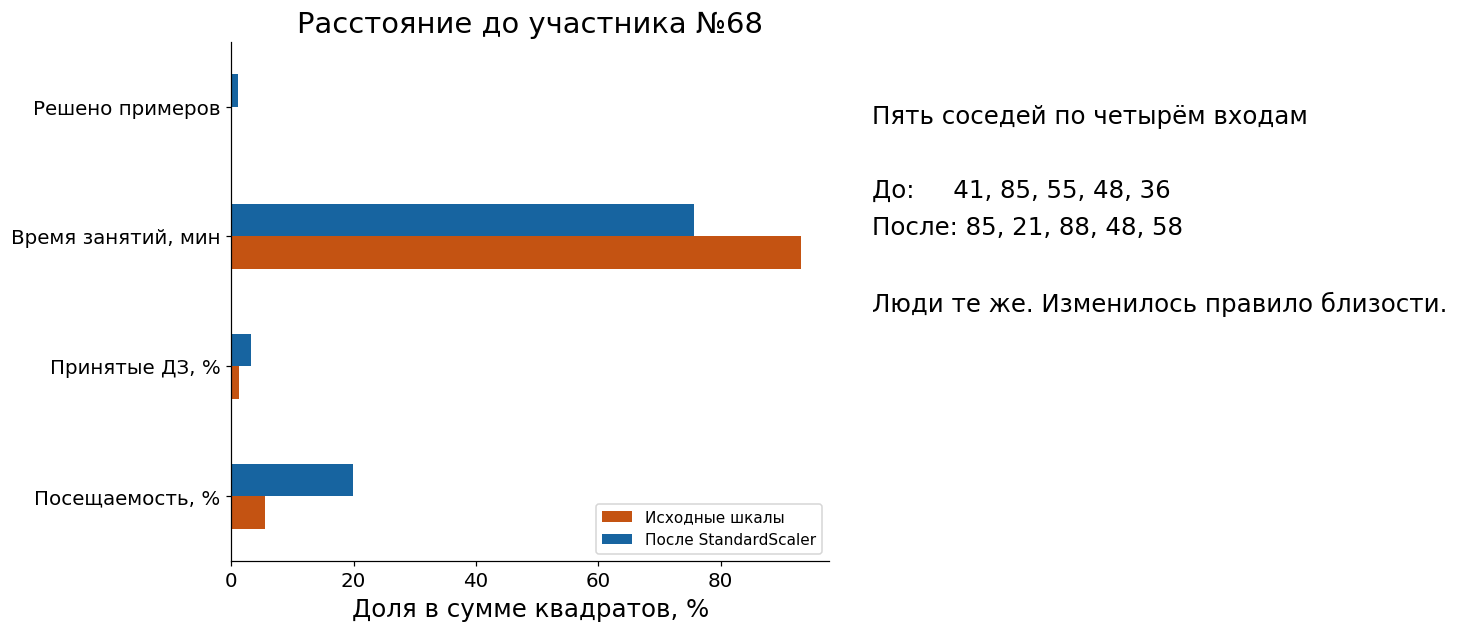

In [39]:
example_index=raw_square_parts['Время занятий, мин'].idxmax()
raw_parts=raw_square_parts.loc[example_index]
scaled_parts=scaled_square_parts.loc[example_index]
distance_shares=pd.DataFrame({'Исходные шкалы':raw_parts/raw_parts.sum()*100,
                              'После StandardScaler':scaled_parts/scaled_parts.sum()*100})
fig,axes=plt.subplots(1,2,figsize=(14,6))
distance_shares.plot.barh(ax=axes[0],color=[ORANGE,BLUE])
axes[0].set(xlabel='Доля в сумме квадратов, %',title=f'Расстояние до участника №{int(multi_train.loc[example_index,"Номер"])}')
axes[0].legend(loc='lower right',fontsize=10)
axes[1].axis('off')
lines=['Пять соседей по четырём входам','',
       'До:     '+', '.join(map(str,raw_neighbors['Номер'])),
       'После: '+', '.join(map(str,scaled_neighbors['Номер'])),'',
       'Люди те же. Изменилось правило близости.']
axes[1].text(.03,.88,'\n'.join(lines),va='top',fontsize=16,linespacing=1.7)
plt.tight_layout();plt.show()

### 🟨❗ Четыре входа — те же fit и predict

Дереву разрешим глубину 2, как раньше. kNN снова берёт пять соседей, теперь расстояния считаются по четырём преобразованным столбцам. `fit` дерева подбирает условия; `fit` kNN сохраняет обучающие примеры для последующего поиска. **Оба получают один и тот же y и одних и тех же людей.**

Получим ответы для новой заявки, затем проверим оба метода на отложенных 25 участниках. Настройки заданы заранее; по этой маленькой проверке не подбираем лучший k и глубину.

**Что делает следующая ячейка.** Создаёт и обучает два классификатора с четырьмя входами. Сверяет ответ kNN с ручными голосами соседей для новой заявки. Для проверки вычисляет accuracy и сохраняет две таблицы ошибок. `predict` возвращает массив, `[0]` берёт ответ единственной заявки.

In [40]:
multi_tree=DecisionTreeClassifier(max_depth=2,random_state=42)
multi_tree.fit(X_multi_train,y_multi_train)
multi_knn=KNeighborsClassifier(n_neighbors=5)
multi_knn.fit(X_multi_train_scaled,y_multi_train)
multi_knn_answer=int(multi_knn.predict(multi_query_scaled)[0])
print('Новая заявка, дерево:',int(multi_tree.predict(multi_query)[0]))
print('Новая заявка, kNN:',multi_knn_answer)
print('Ручной ответ совпал с kNN:',multi_knn_answer==multi_manual_prediction)
multi_tree_predictions=multi_tree.predict(X_multi_valid)
multi_knn_predictions=multi_knn.predict(X_multi_valid_scaled)
multi_tree_confusion=confusion_matrix(y_multi_valid,multi_tree_predictions,labels=[0,1])
multi_knn_confusion=confusion_matrix(y_multi_valid,multi_knn_predictions,labels=[0,1])
display(pd.DataFrame({'Метод':['Дерево: четыре входа','kNN: четыре входа, шкалы приведены'],
                      'Верных ответов':[(multi_tree_predictions==y_multi_valid).sum(),(multi_knn_predictions==y_multi_valid).sum()],
                      'Из скольких':[len(y_multi_valid)]*2,
                      'Accuracy':[accuracy_score(y_multi_valid,multi_tree_predictions),accuracy_score(y_multi_valid,multi_knn_predictions)]}))

Новая заявка, дерево: 1
Новая заявка, kNN: 1
Ручной ответ совпал с kNN: True


,Метод,Верных ответов,Из скольких,Accuracy
0,Дерево: четыре входа,24,25,0.96
1,"kNN: четыре входа, шкалы приведены",23,25,0.92


### 👁 Какие условия выбрало дерево из четырёх доступных входов?

Схема по-прежнему читается сверху вниз. В каждом блоке выбран один из входных столбцов и одна найденная граница. У нового участника берём значение **именно указанного столбца**. Затем идём по «Да» или «Нет».

Количество доступных столбцов не ограничивает число категорий и не заставляет дерево использовать каждый столбец. Схема показывает реальное обученное правило, а не заранее нарисованный пример.

**Что делает следующая ячейка.** Вспомогательная ячейка читает структуру уже обученного дерева с четырьмя входами и показывает условия и конечные категории. Она не меняет модель и не участвует в расчёте точности.

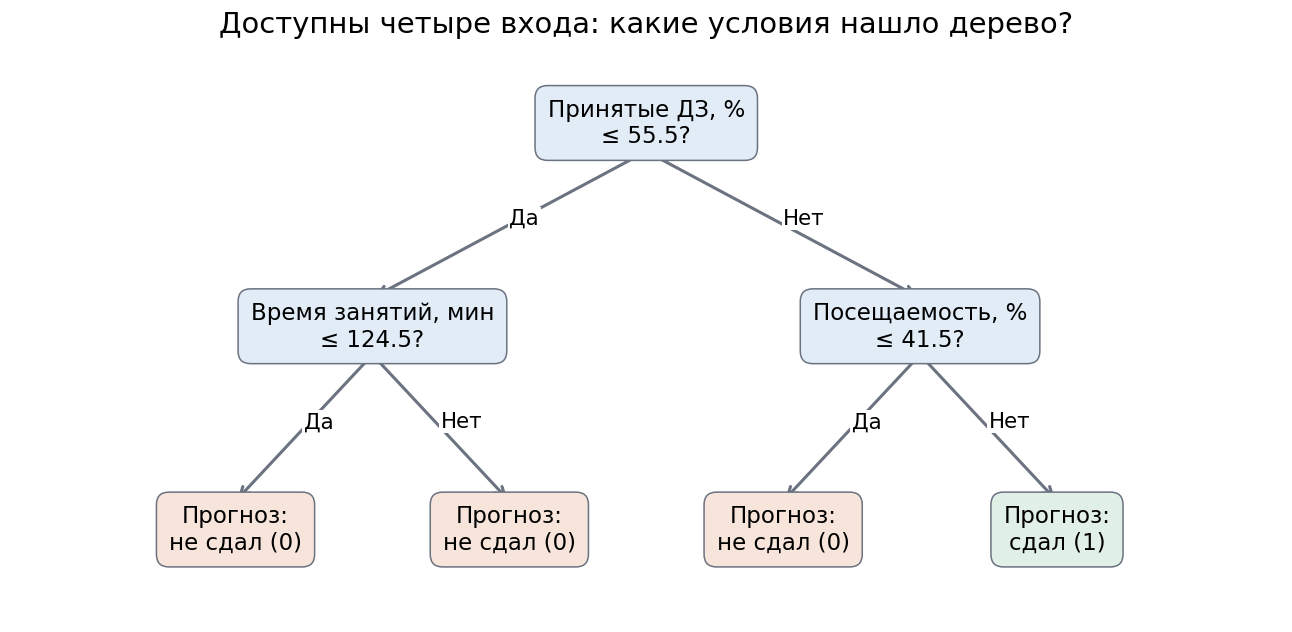

In [41]:
multi_tree_info=multi_tree.tree_
multi_node_positions={}
def place_multi_node(node,x,y,gap):
    multi_node_positions[node]=(x,y)
    if multi_tree_info.children_left[node]!=multi_tree_info.children_right[node]:
        place_multi_node(multi_tree_info.children_left[node],x-gap,y-1,gap/2)
        place_multi_node(multi_tree_info.children_right[node],x+gap,y-1,gap/2)
place_multi_node(0,0.5,2,0.25)
fig,ax=plt.subplots(figsize=(12,6))
for node,(x,y) in multi_node_positions.items():
    is_leaf=multi_tree_info.children_left[node]==multi_tree_info.children_right[node]
    if is_leaf:
        predicted=int(multi_tree.classes_[np.argmax(multi_tree_info.value[node][0])])
        text='Прогноз:'+chr(10)+('сдал (1)' if predicted==1 else 'не сдал (0)')
        face='#e1f0e7' if predicted==1 else '#f7e5db'
    else:
        feature=multi_features[multi_tree_info.feature[node]]
        text=feature+'\n≤ '+f'{multi_tree_info.threshold[node]:g}'+'?'
        face='#e1ecf7'
        for child,answer in [(multi_tree_info.children_left[node],'Да'),(multi_tree_info.children_right[node],'Нет')]:
            cx,cy=multi_node_positions[child]
            ax.annotate('',xy=(cx,cy+.14),xytext=(x,y-.14),
                        arrowprops={'arrowstyle':'->','color':GRAY,'lw':2})
            ax.text((x+cx)/2,(y+cy)/2,answer,fontsize=14,
                    bbox={'facecolor':'white','edgecolor':'none','pad':1})
    ax.text(x,y,text,ha='center',va='center',fontsize=15,
            bbox={'boxstyle':'round,pad=.55','facecolor':face,'edgecolor':GRAY})
ax.set(xlim=(-.08,1.08),ylim=(-.45,2.4),title='Доступны четыре входа: какие условия нашло дерево?')
ax.axis('off');plt.tight_layout();plt.show()

**Что делает следующая ячейка.** По той же новой заявке проходит выбранные деревом условия и печатает путь словами. В каждой строке показаны имя признака, его значение, граница и выбранная ветка. Сверяет конечную категорию с predict.

In [42]:
multi_path_info=multi_tree.tree_
node=0
while multi_path_info.children_left[node]!=multi_path_info.children_right[node]:
    column=multi_features[multi_path_info.feature[node]]
    value=float(multi_query.iloc[0][column])
    threshold=float(multi_path_info.threshold[node])
    go_left=value<=threshold
    print(f'{column}: {value:g} ≤ {threshold:g}?', 'Да' if go_left else 'Нет')
    node=multi_path_info.children_left[node] if go_left else multi_path_info.children_right[node]
multi_path_answer=int(multi_tree.classes_[np.argmax(multi_path_info.value[node][0])])
print('В конце пути:',multi_path_answer,'—','сдал' if multi_path_answer==1 else 'не сдал')
print('Совпало с predict:',multi_path_answer==int(multi_tree.predict(multi_query)[0]))

Принятые ДЗ, %: 60 ≤ 55.5? Нет
Посещаемость, %: 60 ≤ 41.5? Нет
В конце пути: 1 — сдал
Совпало с predict: True


### 🟨❗ Помогли ли новые признаки? Сравним с двумя входами

Для kNN сравним два и четыре признака **с приведением шкал в обоих случаях**. Иначе одновременно менялись бы две вещи: состав входов и правило расстояния. Для дерева в обоих опытах оставляем глубину 2 и исходные числа.

Два новых столбца не гарантируют улучшения: они могут повторять старые сведения или добавлять шум. В нашем файле исходы вымышленные; результат сравнения относится только к этому примеру.

**Что делает следующая ячейка.** Для двух признаков создаёт свой scaler только по обучению и обучает ещё один kNN с пятью соседями. В итоговой таблице для каждого способа сравнивает два и четыре входа на том же составе проверки. У дерева берём уже полученный результат с двумя входами.

In [43]:
two_scaler=StandardScaler()
two_scaler.fit(multi_train[exam_features])
X_two_train_scaled=pd.DataFrame(two_scaler.transform(multi_train[exam_features]),columns=exam_features,index=multi_train.index)
X_two_valid_scaled=pd.DataFrame(two_scaler.transform(multi_valid[exam_features]),columns=exam_features,index=multi_valid.index)
two_scaled_knn=KNeighborsClassifier(n_neighbors=5)
two_scaled_knn.fit(X_two_train_scaled,y_multi_train)
two_scaled_predictions=two_scaled_knn.predict(X_two_valid_scaled)
multi_comparison=pd.DataFrame({'Способ':['Дерево, 2 входа','Дерево, 4 входа','kNN, 2 входа, scaler','kNN, 4 входа, scaler'],
                              'Accuracy':[exam_accuracy,accuracy_score(y_multi_valid,multi_tree_predictions),
                                          accuracy_score(y_multi_valid,two_scaled_predictions),accuracy_score(y_multi_valid,multi_knn_predictions)]})
display(multi_comparison)

,Способ,Accuracy
0,"Дерево, 2 входа",0.96
1,"Дерево, 4 входа",0.96
2,"kNN, 2 входа, scaler",1.00
3,"kNN, 4 входа, scaler",0.92


**Что делает следующая ячейка.** Рисует число верных ответов для каждого опыта и два вида ошибок четырёхпризнаковых моделей. На матрицах строка — настоящий ответ, столбец — прогноз. Их оси подписаны словами, а числа внутри — количество участников.

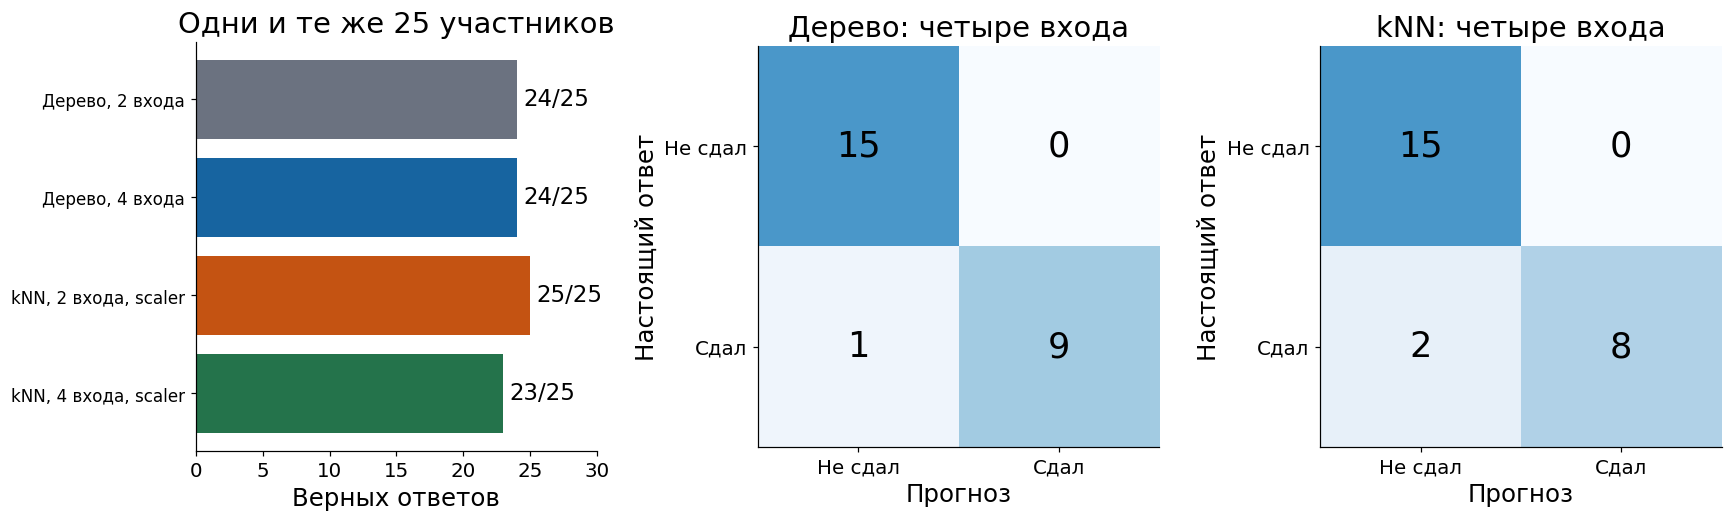

In [44]:
fig,axes=plt.subplots(1,3,figsize=(16,5))
bars=axes[0].barh(multi_comparison['Способ'],multi_comparison['Accuracy']*len(multi_valid),color=[GRAY,BLUE,ORANGE,GREEN])
axes[0].bar_label(bars,labels=[f'{int(round(v*len(multi_valid)))}/{len(multi_valid)}' for v in multi_comparison['Accuracy']],padding=4)
axes[0].set(xlim=(0,len(multi_valid)*1.2),xlabel='Верных ответов',title='Одни и те же 25 участников')
axes[0].invert_yaxis();axes[0].tick_params(axis='y',labelsize=11)
for ax,cm,title in [(axes[1],multi_tree_confusion,'Дерево: четыре входа'),(axes[2],multi_knn_confusion,'kNN: четыре входа')]:
    ax.imshow(cm,cmap='Blues',vmin=0,vmax=len(multi_valid))
    for row in range(2):
        for col in range(2):ax.text(col,row,str(cm[row,col]),ha='center',va='center',fontsize=23)
    ax.set_xticks([0,1],['Не сдал','Сдал']);ax.set_yticks([0,1],['Не сдал','Сдал'])
    ax.set(xlabel='Прогноз',ylabel='Настоящий ответ',title=title)
plt.tight_layout();plt.show()

## ❓ Вопросы и выводы: что переносим на Titanic?

1. Категория — ответ задачи, а число входных столбцов — сколько сведений об объекте мы используем. Шесть входов не означают шесть категорий.
2. Дерево выбирает условия по уменьшению смешанности обучающих групп; kNN считает близость и голоса обучающих соседей.
3. Сначала откладываем проверочных людей. Заполнение и приведение шкал настраиваем на обучении; к проверке применяем готовые правила.
4. Качество считаем по известным исходам отложенных примеров. Новая заявка без исхода не позволяет вычислить accuracy.
5. Больше признаков или сложнее модель не означают автоматически лучшее качество.

На Titanic одна строка — пассажир, ответ — «выжил / не выжил». Будем использовать шесть характеристик: класс билета, пол, возраст, стоимость проезда, число братьев/сестёр/супругов, число родителей/детей. Подготовим их в практике и продолжим дома. Данные исторические: модель ищет связи, а не объясняет причины судьбы отдельного человека.

# 🏠 Самостоятельная работа в этом же ноутбуке

Пишите код в уже созданных Code-ячейках. Добавлять новые ячейки не требуется. Блок **? ВЫВОДЫ** — место для собственного объяснения результатов словами. Перед сдачей перезапустите ядро, выполните все ячейки сверху вниз и сохраните выводы.

Сдайте один файл **`solution.ipynb`** с кодом, таблицами, графиками и ответами. Отдельные картинки, CSV и текстовый отчёт не требуются. Дедлайн сообщает преподаватель.

На занятии выполняем только задания **П1–П2**. Дома продолжаем с **Д1–Д5**. Файл `Урок_13_Классификация_Titanic.csv` лежит рядом с ноутбуком; новая загрузка с Kaggle не нужна. Это исходная учебная таблица на 891 пассажира с известным `Survived`, а не соревновательный файл без ответов.

## Что сделать дома

Завершите П1–П2, если не успели на занятии, затем выполните Д1–Д5:

1. Заполните неизвестные входные значения средними **обучающей** части.
2. Сравните ориентир большинства с деревом по шести признакам.
3. Приведите шкалы по обучению и обучите kNN с пятью соседями; сравните методы на тех же пассажирах.
4. Покажите матрицу ошибок и разберите два ошибочных ответа.
5. Получите прогноз для новой заявки и объясните, где действительно проверено качество.

Подробные условия и места для кода находятся ниже. В ячейках «? ВЫВОДЫ» напишите собственные объяснения. Демонстрационные расчёты про экзамен можно оставить выполненными; новая самостоятельная работа — про Titanic. Перед сдачей сохраните копию этого ноутбука как `solution.ipynb`, перезапустите ядро, выполните всё сверху вниз и сохраните результаты.


## 🟨❗ Инструменты и входные признаки

`pandas` работает с таблицами, `numpy` — с числами, `matplotlib` — с графиками. `scikit-learn` содержит модели и инструменты подготовки. Импорт не создаёт прогнозов. Если библиотеки нет, установите `%pip install scikit-learn` и перезапустите ядро.

| Инструмент | Задача |
|---|---|
| `train_test_split` | Отложить разные строки для проверки |
| `SimpleImputer(strategy='mean')` | Запомнить среднее входного столбца по обучению, затем заполнить пропуски |
| `StandardScaler` | Запомнить среднее и разброс входа по обучению, затем привести шкалы |
| `DecisionTreeClassifier` | Подобрать последовательность условий для категории |
| `KNeighborsClassifier` | Сохранить примеры и голосовать по ближайшим |
| `accuracy_score` | Посчитать долю верных категорий |
| `confusion_matrix` | Посчитать, какие категории перепутали |

| Исходное поле | Рабочее название | Содержание |
|---|---|---|
| PassengerId | Номер | Номер пассажира; для проверки пересечений, не вход модели |
| Pclass | Класс | 1, 2 или 3 — класс билета |
| Sex | Пол | male/female — пол в исходной таблице |
| Age | Возраст | Возраст в годах; дробное значение у ребёнка допустимо |
| Fare | Проезд | Стоимость проезда в исходных денежных единицах |
| SibSp | Родственники рядом | Братья, сёстры, супруги на борту |
| Parch | Родители и дети | Родители и дети на борту |
| Survived | Выжил | Известный ответ: 0 — нет, 1 — да |

Остальные поля в этой работе не используем. Это **шесть входных столбцов**, один номер и один ответ.

Для числового учебного примера заменим male на 0, female на 1 через `map`. Это условные коды двух значений, а не утверждение, что одна категория «больше» другой. Для трёх и более неупорядоченных категорий простая нумерация может давать ложный порядок; их кодирование здесь не рассматриваем. Класс билета оставим числовым порядковым входом как упрощение примера.

**Что делает следующая ячейка.** Подключает библиотеки и отдельные инструменты scikit-learn. Пока не читает данные и не обучает модели.

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

## ⭐ П1. Подготовим понятную рабочую таблицу

1. Прочитайте весь `Урок_13_Классификация_Titanic.csv` в `raw_data`. Выведите размеры, список столбцов, первые строки.
2. По таблице выше выберите восемь полей в `passengers = raw_data[...].copy()`.
3. Создайте словарь `column_names` вида «исходное название → рабочее название» и выполните `rename(columns=column_names)`.
4. Покажите пропуски, полные повторы, повторы номера и уникальные ответы. Проверьте класс 1–3, возраст и проезд неотрицательные, количества родственников целые неотрицательные. Пропуск возраста пока оставьте.
5. Закодируйте `Пол` через `map({'male':0,'female':1})`; убедитесь, что новых пропусков не появилось.

`copy` создаёт отдельную таблицу. `rename` меняет заголовки, а `map` — значения выбранного столбца по словарю. Не меняйте имена переменных на русские.

**Что делает следующая ячейка.** Здесь ваш код должен прочитать и осмотреть исходник, выбрать рабочую копию, переименовать поля и проверить смысл значений. Сначала покажите найденное; не вызывайте общее удаление строк с любым пропуском.

In [46]:
# Напишите решение здесь.
# 1. Чтение и первый осмотр
raw_data = pd.read_csv('Урок_13_Классификация_Titanic.csv')
print('Размеры:', raw_data.shape)
print('Столбцы:', raw_data.columns.tolist())
display(raw_data.head())

# 2. Рабочая копия из восьми полей
passengers = raw_data[['PassengerId', 'Pclass', 'Sex', 'Age', 'Fare',
                       'SibSp', 'Parch', 'Survived']].copy()

# 3. Рабочие названия
column_names = {'PassengerId': 'Номер', 'Pclass': 'Класс', 'Sex': 'Пол',
                'Age': 'Возраст', 'Fare': 'Проезд', 'SibSp': 'Родственники рядом',
                'Parch': 'Родители и дети', 'Survived': 'Выжил'}
passengers = passengers.rename(columns=column_names)

# 4. Проверки
print('\nПропуски по столбцам:')
display(passengers.isna().sum().to_frame('Пропусков'))
print('Полных повторов строк:', passengers.duplicated().sum())
print('Повторов номера:', passengers['Номер'].duplicated().sum())
print('Уникальные ответы:', sorted(passengers['Выжил'].unique().tolist()))
print('Класс только 1–3:', passengers['Класс'].isin([1, 2, 3]).all())
print('Возраст неотрицательный (без пропусков):', (passengers['Возраст'].dropna() >= 0).all())
print('Проезд неотрицательный:', (passengers['Проезд'] >= 0).all())
for col in ['Родственники рядом', 'Родители и дети']:
    s = passengers[col]
    print(f'{col}: целые и ≥ 0:', ((s >= 0) & (s == s.round())).all())

# 5. Кодирование пола
na_before = passengers.isna().sum().sum()
passengers['Пол'] = passengers['Пол'].map({'male': 0, 'female': 1})
print('\nНовых пропусков после map:', passengers.isna().sum().sum() - na_before)
display(passengers.head())

Размеры: (891, 12)
Столбцы: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.050,NaN,S



Пропуски по столбцам:


,Пропусков
Номер,0
Класс,0
Пол,0
Возраст,177
Проезд,0
Родственники рядом,0
Родители и дети,0
Выжил,0


Полных повторов строк: 0
Повторов номера: 0
Уникальные ответы: [0, 1]
Класс только 1–3: True
Возраст неотрицательный (без пропусков): True
Проезд неотрицательный: True
Родственники рядом: целые и ≥ 0: True
Родители и дети: целые и ≥ 0: True

Новых пропусков после map: 0


,Номер,Класс,Пол,Возраст,Проезд,Родственники рядом,Родители и дети,Выжил
0,1,3,0,22.0,7.250,1,0,0
1,2,1,1,38.0,71.283,1,0,1
2,3,3,1,26.0,7.925,0,0,1
3,4,1,1,35.0,53.100,1,0,1
4,5,3,0,35.0,8.050,0,0,0


### ❓ ? ВЫВОДЫ

Что описывает одна строка? Какие пропуски нашли? Почему нельзя считать неизвестный возраст нулём?

**Мой ответ:**

Что описывает одна строка?
Одна строка описывает одного пассажира Titanic. В ней номер, класс билета, пол, возраст, стоимость проезда, число родственников рядом, число родителей и детей на борту и известный исход: выжил или нет. Всего 891 пассажир.

Какие пропуски нашли?
Пропуски нашлись только в столбце «Возраст»: 177 из 891 значений неизвестны. В остальных семи столбцах пропусков нет. Полных повторов строк и повторов номера нет, значения классов, возраста, проезда и количества родственников допустимы. После замены пола на 0 и 1 новых пропусков не появилось.

Почему нельзя считать неизвестный возраст нулём?
Ноль означает, что пассажиру меньше года, а у нас его возраст просто не записан. Если подставить 0, мы выдадим неизвестное за конкретный факт и появятся сотни «младенцев». Это исказит среднее и расстояния между пассажирами и собьёт модель, особенно kNN. Поэтому пропуски оставляем до разделения на обучение и проверку и позже заполняем средним по обучающей части.

## ⭐ П2. Одни пассажиры учат, другие проверяют

Создайте `train_data, valid_data = train_test_split(passengers, test_size=0.25, random_state=42, stratify=passengers['Выжил'])`.

- `test_size=0.25` откладывает четверть строк; округление размера делает функция.
- `random_state=42` повторяет выбор при перезапуске.
- `stratify=...` сохраняет примерно одинаковые доли категорий в двух частях. Это не раздельное обучение на каждой категории.

Выведите размеры частей, число общих номеров и количество 0/1 в каждой. Подготовьте список `features` из шести входов, `target='Выжил'`, затем `X_train_raw, X_valid_raw, y_train, y_valid`. Номер и ответ в `features` не включайте.

Цель проверки: получить прогноз на пассажирах, которые не участвовали в fit, затем сравнить его с их сохранёнными исходами. Строки распределяем один раз **до вычисления средних**.

**Что делает следующая ячейка.** Ваш код разделяет строки и выбирает входы и ответы из каждой части. Здесь ещё нет обучения, заполнения и оценки точности.

In [47]:
# Напишите решение здесь.
# Разделение: строки распределяем один раз, до любых средних
train_data, valid_data = train_test_split(
    passengers, test_size=0.25, random_state=42, stratify=passengers['Выжил'])

# Входы и ответ
features = ['Класс', 'Пол', 'Возраст', 'Проезд',
            'Родственники рядом', 'Родители и дети']
target = 'Выжил'

X_train_raw = train_data[features]
y_train = train_data[target]
X_valid_raw = valid_data[features]
y_valid = valid_data[target]

# Проверки
print('Все пассажиры:', len(passengers))
print('Обучение:', len(train_data), '| Проверка:', len(valid_data))
print('Общих номеров в двух частях:', valid_data['Номер'].isin(train_data['Номер']).sum())
display(pd.DataFrame({'Обучение': y_train.value_counts().sort_index(),
                      'Проверка': y_valid.value_counts().sort_index()})
        .rename_axis('Выжил'))
print('Номер и ответ во входах:', 'Номер' in features or target in features)

Все пассажиры: 891
Обучение: 668 | Проверка: 223
Общих номеров в двух частях: 0


,Обучение,Проверка
Выжил,,
0,412,137
1,256,86


Номер и ответ во входах: False


### ❓ ? ВЫВОДЫ

Почему проверка на тех же пассажирах, что обучение, не заменяет эту проверку? Почему нельзя включить «Выжил» в X?

**Мой ответ:**

Почему проверка на тех же пассажирах, что обучение, не заменяет эту проверку?
Модель уже видела этих пассажиров вместе с их ответами и могла просто подстроиться под них, поэтому высокая accuracy на знакомых примерах ничего не говорит о новых. Отложенные 223 пассажира не участвовали в fit. Только на них можно честно сравнить прогноз с известным исходом и понять, как модель поведёт себя на новых людях.

Почему нельзя включить «Выжил» в X?
Это значит самим подсказать модели правильный ответ. У новой заявки такого значения нет, поэтому модель на практике работать не сможет, а её accuracy на проверке будет искусственно близка к 100%.

## 🏠 Домашняя часть. Продолжаем с теми же таблицами

Не делите пассажиров заново между заданиями. Не заполняйте y средним. Настройки моделей ниже заданы для сравнения, а не получены перебором по проверочным ответам.

У инструментов подготовки две разные команды:

- **fit** у `SimpleImputer` вычисляет и запоминает средние обучающих столбцов; **transform** заполняет пустые входы этими числами.
- **fit** у `StandardScaler` вычисляет и запоминает средние и разбросы обучающих столбцов; **transform** вычитает и делит, используя уже запомнённые величины.
- **fit** у дерева ищет условия по X и известному y. **predict** применяет эти условия.
- **fit** у kNN сохраняет входы и известные категории соседей. **predict** ищет ближайших и считает голоса.

`pd.DataFrame(массив, columns=features, index=...)` возвращает заголовки и номера строк результату преобразования. Средние и масштабы проверки заново не учим.

## 🏠 Д1. Заполним неизвестные входы

Создайте `imputer = SimpleImputer(strategy='mean')`. Вызовите `fit(X_train_raw)` — **без y**. Покажите `statistics_` в таблице с названиями столбцов. Примените `transform` к обеим частям и верните результаты в DataFrame `X_train`, `X_valid` с теми же столбцами и индексами.

Покажите пропуски до и после. Сравните сохранённое среднее возраста со средним `X_train_raw['Возраст'].mean()`. Не используйте среднее всей исходной таблицы.

**Что делает следующая ячейка.** Ваш код учит правило заполнения на обучении и применяет его к обеим частям. Ответы y остаются исходными.

In [48]:
# Напишите решение здесь.
# Правило заполнения учим только на обучении (без y)
imputer = SimpleImputer(strategy='mean')
imputer.fit(X_train_raw)
display(pd.DataFrame({'Сохранённое среднее обучения': imputer.statistics_}, index=features))

# Применяем готовое правило к обеим частям, возвращаем названия и индексы
X_train = pd.DataFrame(imputer.transform(X_train_raw), columns=features, index=X_train_raw.index)
X_valid = pd.DataFrame(imputer.transform(X_valid_raw), columns=features, index=X_valid_raw.index)

display(pd.DataFrame({'Обучение до': X_train_raw.isna().sum(),
                      'Обучение после': X_train.isna().sum(),
                      'Проверка до': X_valid_raw.isna().sum(),
                      'Проверка после': X_valid.isna().sum()}))

age_mean_saved = imputer.statistics_[features.index('Возраст')]
print('Среднее возраста в imputer:', round(age_mean_saved, 3))
print('X_train_raw["Возраст"].mean():', round(X_train_raw['Возраст'].mean(), 3))
print('Совпадают:', np.isclose(age_mean_saved, X_train_raw['Возраст'].mean()))
print('Для сравнения, среднее всей таблицы (не используем):', round(passengers['Возраст'].mean(), 3))
print('Ответы y не менялись, пропусков в y:', y_train.isna().sum() + y_valid.isna().sum())

,Сохранённое среднее обучения
Класс,2.313
Пол,0.350
Возраст,29.932
Проезд,31.177
Родственники рядом,0.464
Родители и дети,0.376


,Обучение до,Обучение после,Проверка до,Проверка после
Класс,0,0,0,0
Пол,0,0,0,0
Возраст,131,0,46,0
Проезд,0,0,0,0
Родственники рядом,0,0,0,0
Родители и дети,0,0,0,0


Среднее возраста в imputer: 29.932
X_train_raw["Возраст"].mean(): 29.932
Совпадают: True
Для сравнения, среднее всей таблицы (не используем): 29.699
Ответы y не менялись, пропусков в y: 0


### ❓ ? ВЫВОДЫ

Почему transform проверки должен использовать среднее обучения? Почему нельзя так заполнить неизвестное «Выжил»?

**Мой ответ:**

Почему transform проверки должен использовать среднее обучения?
Проверочные пассажиры изображают людей, которых модель ещё не видела. Правило заполнения — часть обучения, поэтому его выучили только на 668 обучающих строках: средний возраст 29,93 года. Если бы среднее считали по проверке или по всей таблице (там 29,70), сведения о проверочных людях просочились бы в подготовку, и оценка стала бы нечестной. Кроме того, у одной новой заявки «своего среднего» вообще нет: ей тоже нужно готовое число из обучения. После transform пропусков не осталось: 131 в обучении и 46 в проверке заменены одним и тем же числом.

Почему нельзя так заполнить неизвестное «Выжил»?
«Выжил» — это ответ, который модель должна предсказать, а не вход. Средний ответ (≈0,38) не является ни 0, ни 1 и не является правдой о человеке. Если придумать ответ, мы будем учить и проверять модель на выдуманных исходах. Строки без известного ответа не годятся ни для обучения, ни для подсчёта accuracy. В нашей таблице в «Выжил» пропусков нет, а imputer обучался без y.

## 🏠 Д2. Ориентир и дерево по шести характеристикам

1. Найдите наиболее частую категорию **обучения** через `y_train.mode().iloc[0]`. Всем проверочным пассажирам предскажите её: `np.full(len(y_valid), baseline_class)`.
2. Создайте `tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)`. `max_depth=3` разрешает до трёх условий на одном пути; `random_state` повторяет случайные решения алгоритма.
3. Вызовите fit на `X_train,y_train`, затем predict на `X_valid`. Последней строкой выведите понятное сообщение, чтобы не получать только карточку модели.
4. Сравните accuracy дерева с ориентиром. Постройте матрицу ошибок дерева с `labels=[0,1]`, назвав строки «Факт» и столбцы «Прогноз».

Accuracy — доля совпавших категорий; это не вероятность выживания одной строки. В матрице строки — настоящие ответы, столбцы — прогнозы.

**Что делает следующая ячейка.** Ваш код получает простой ориентир и обучает дерево. Для обоих оценивает ответы на одних проверочных пассажирах.

In [49]:
# Напишите решение здесь.
# 1. Ориентир: самая частая категория обучения
baseline_class = int(y_train.mode().iloc[0])
baseline_predictions = np.full(len(y_valid), baseline_class)
baseline_accuracy = accuracy_score(y_valid, baseline_predictions)

# 2–3. Дерево глубины 3
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_valid)
tree_accuracy = accuracy_score(y_valid, tree_predictions)

# 4. Сравнение и матрица ошибок дерева
print('Самая частая категория обучения:', baseline_class, '(не выжил)' if baseline_class == 0 else '(выжил)')
print(f'Ориентир: {int((baseline_predictions == y_valid).sum())} из {len(y_valid)} верно, accuracy = {baseline_accuracy:.3f}')
print(f'Дерево:   {int((tree_predictions == y_valid).sum())} из {len(y_valid)} верно, accuracy = {tree_accuracy:.3f}')

tree_confusion = confusion_matrix(y_valid, tree_predictions, labels=[0, 1])
display(pd.DataFrame(tree_confusion,
                     index=['Факт: не выжил (0)', 'Факт: выжил (1)'],
                     columns=['Прогноз: не выжил (0)', 'Прогноз: выжил (1)']))
print(f'Дерево обучено (глубина {tree_model.get_depth()}), прогнозы получены для {len(tree_predictions)} проверочных пассажиров.')

Самая частая категория обучения: 0 (не выжил)
Ориентир: 137 из 223 верно, accuracy = 0.614
Дерево:   175 из 223 верно, accuracy = 0.785


,Прогноз: не выжил (0),Прогноз: выжил (1)
Факт: не выжил (0),131,6
Факт: выжил (1),42,44


Дерево обучено (глубина 3), прогнозы получены для 223 проверочных пассажиров.


### ❓ ? ВЫВОДЫ

Лучше ли дерево простого ориентира на этой проверке? Сколько выживших оно отнесло к невыжившим и наоборот?

**Мой ответ:**

Лучше ли дерево простого ориентира на этой проверке?
Да. Ориентир всем предсказывает самую частую категорию обучения «не выжил» и угадывает 137 из 223 (accuracy 0,614): это просто доля невыживших в проверке. Дерево глубины 3 по шести признакам угадало 175 из 223 (0,785), то есть на 38 пассажиров больше, примерно +17 процентных пунктов.

Сколько выживших оно отнесло к невыжившим и наоборот?
По матрице ошибок 42 выживших дерево отнесло к невыжившим (это больше половины из 86 выживших в проверке). Ещё 6 невыживших оно ошибочно посчитало выжившими. Верно предсказаны 131 невыживший и 44 выживших. Дерево гораздо чаще «хоронит» выживших, чем наоборот. Его первое условие — пол: почти всех мужчин (кроме мальчиков до 3,5 лет) оно относит к невыжившим, а «выжил» предсказывает в основном женщинам 1–2 класса и женщинам 3 класса с самым дешёвым билетом. Поэтому выжившие мужчины и многие выжившие женщины 3 класса попадают в ошибки.

## 🏠 Д3. Пять соседей по шести входам

Создайте `scaler = StandardScaler()`, обучите его на уже заполненном `X_train`. Покажите `mean_` и `scale_`. Преобразуйте обе части в `X_train_scaled`, `X_valid_scaled`, сохранив столбцы и индексы.

Создайте `knn_model = KNeighborsClassifier(n_neighbors=5)`: `n_neighbors=5` означает пять обучающих соседей с равными голосами. Расстояние по умолчанию здесь евклидово — корень из суммы шести квадратов отличий. Обучите на преобразованном обучении и y, получите `knn_predictions` для преобразованной проверки.

Выведите таблицу `comparison` с accuracy ориентира, дерева и kNN; постройте столбчатый график. Шкалу accuracy на графике начните с нуля.

**Что делает следующая ячейка.** Ваш код приводит шкалы по обучению, применяет их к проверке, обучает kNN и сравнивает три способа. Не передавайте в kNN исходную проверку после обучения на преобразованной.

,mean_,scale_
Класс,2.313,0.831
Пол,0.350,0.477
Возраст,29.932,12.949
Проезд,31.177,47.422
Родственники рядом,0.464,0.999
Родители и дети,0.376,0.832


,Способ,Верных из 223,Accuracy
0,Ориентир большинства,137,0.614
1,"Дерево, глубина 3",175,0.785
2,"kNN, 5 соседей",173,0.776


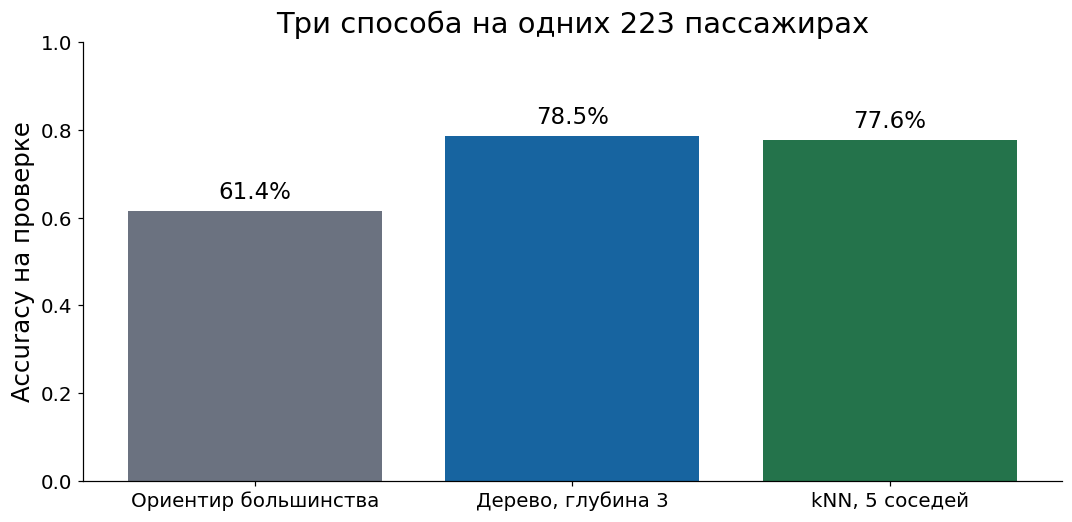

In [50]:
# Напишите решение здесь.
# Приведение шкал: учим только на заполненном обучении
scaler = StandardScaler()
scaler.fit(X_train)
display(pd.DataFrame({'mean_': scaler.mean_, 'scale_': scaler.scale_}, index=features))

X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=features, index=X_train.index)
X_valid_scaled = pd.DataFrame(scaler.transform(X_valid), columns=features, index=X_valid.index)

# kNN по шести преобразованным входам
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_predictions = knn_model.predict(X_valid_scaled)
knn_accuracy = accuracy_score(y_valid, knn_predictions)

comparison = pd.DataFrame({
    'Способ': ['Ориентир большинства', 'Дерево, глубина 3', 'kNN, 5 соседей'],
    'Верных из 223': [int((baseline_predictions == y_valid).sum()),
                      int((tree_predictions == y_valid).sum()),
                      int((knn_predictions == y_valid).sum())],
    'Accuracy': [baseline_accuracy, tree_accuracy, knn_accuracy]})
display(comparison)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(comparison['Способ'], comparison['Accuracy'], color=['#6b7280', '#1764a0', '#24734b'])
ax.bar_label(bars, labels=[f'{a:.1%}' for a in comparison['Accuracy']], padding=5)
ax.set(ylim=(0, 1), ylabel='Accuracy на проверке', title='Три способа на одних 223 пассажирах')
plt.tight_layout(); plt.show()

### ❓ ? ВЫВОДЫ

Какой способ оказался точнее здесь? Почему разные денежные и возрастные шкалы важны для поиска соседей? Можно ли утверждать, что победивший метод всегда лучше?

**Мой ответ:**

Какой способ оказался точнее здесь?
На этой проверке точнее всех дерево: 175 из 223 (78,5%). kNN с пятью соседями угадал 173 из 223 (77,6%), ориентир 137 из 223 (61,4%). Оба обученных метода заметно лучше ориентира, а разница между деревом и kNN — всего 2 пассажира, меньше одного процентного пункта.

Почему разные денежные и возрастные шкалы важны для поиска соседей?
kNN считает евклидово расстояние: складывает квадраты отличий по всем шести входам. Проезд в обучении разбросан с масштабом ≈47,4, возраст ≈12,9, а пол только 0/1 (масштаб ≈0,48). Без приведения шкал разница в 50 денежных единиц дала бы квадрат 2500, а различие по полу — всего 1. Соседи выбирались бы почти только по стоимости билета и возрасту, а пол и класс почти не влияли бы. StandardScaler переводит каждый вход в «число разбросов от среднего обучения», и все признаки получают сопоставимый вес. Дереву это не нужно: оно сравнивает один признак с границей.

Можно ли утверждать, что победивший метод всегда лучше?
Нет. Проверка одна и небольшая: 223 человека, и разница в 2 ответа может смениться при другом random_state, других настройках (глубина, k) или других данных. Мы проверили только одно разделение и одни настройки, причём заданные заранее. Чтобы делать выводы, нужны повторные разделения или кросс-валидация, а для выбора настроек — отдельная часть данных.

## 🏠 Д4. Посмотрим, кого перепутали

Для kNN вычислите матрицу ошибок `confusion_matrix(y_valid,knn_predictions,labels=[0,1])` и покажите её таблицей и рисунком с подписями категорий. `imshow` показывает двумерную таблицу цветом, `text` подписывает число внутри клетки.

Создайте `check` из номеров, шести исходных признаков и настоящего ответа **проверки**. Добавьте прогнозы дерева и kNN. Покажите два ошибочных ответа kNN через фильтр `check['kNN'] != check[target]` и `head(2)`. Ничего в проверке после просмотра ошибок не исправляйте специально ради роста accuracy.

**Что делает следующая ячейка.** Ваш код связывает агрегированные ошибки с конкретными пассажирами. Диагональ рисунка — верные ответы, остальные клетки — два разных вида промаха.

,Прогноз: Не выжил (0),Прогноз: Выжил (1)
Факт: Не выжил (0),117,20
Факт: Выжил (1),30,56


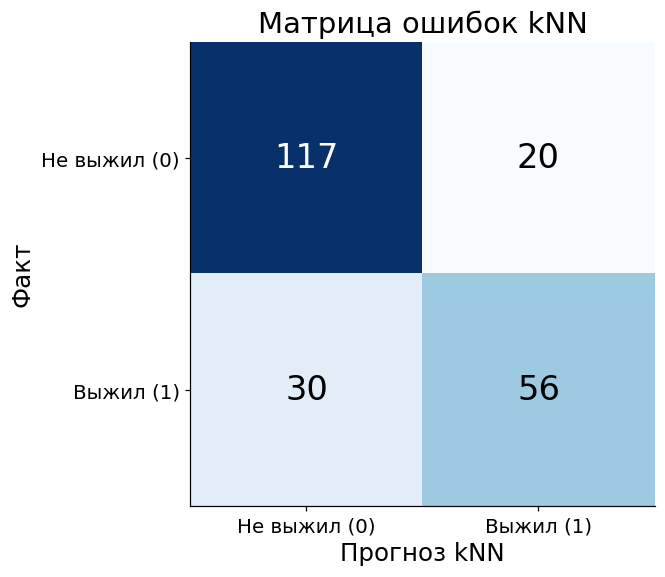

Всего ошибок kNN: 50


,Номер,Класс,Пол,Возраст,Проезд,Родственники рядом,Родители и дети,Выжил,Дерево,kNN
501,502,3,1,21.0,7.75,0,0,0,1,1
347,348,3,1,NaN,16.10,1,0,1,0,0


In [51]:
# Напишите решение здесь.
knn_confusion = confusion_matrix(y_valid, knn_predictions, labels=[0, 1])
class_names = ['Не выжил (0)', 'Выжил (1)']
display(pd.DataFrame(knn_confusion,
                     index=['Факт: ' + n for n in class_names],
                     columns=['Прогноз: ' + n for n in class_names]))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(knn_confusion, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, knn_confusion[i, j], ha='center', va='center', fontsize=22,
                color='white' if knn_confusion[i, j] > knn_confusion.max() / 2 else 'black')
ax.set_xticks([0, 1], class_names); ax.set_yticks([0, 1], class_names)
ax.set(xlabel='Прогноз kNN', ylabel='Факт', title='Матрица ошибок kNN')
plt.tight_layout(); plt.show()

# Связываем ошибки с конкретными пассажирами проверки
check = valid_data[['Номер'] + features + [target]].copy()
check['Дерево'] = tree_predictions
check['kNN'] = knn_predictions
knn_errors = check[check['kNN'] != check[target]]
print('Всего ошибок kNN:', len(knn_errors))
display(knn_errors.head(2))

### ❓ ? ВЫВОДЫ

Прочитайте словами две клетки вне диагонали. По двум показанным ошибкам укажите настоящий исход и прогноз. Почему одного общего процента мало?

**Мой ответ:**

Прочитайте словами две клетки вне диагонали.
Матрица kNN: строка — факт, столбец — прогноз.
- Верхняя правая клетка (20): 20 пассажиров на самом деле не выжили, а kNN предсказал «выжил».
- Нижняя левая клетка (30): 30 пассажиров на самом деле выжили, а kNN предсказал «не выжил».
На диагонали верные ответы: 117 невыживших и 56 выживших. Всего ошибок 50 из 223.

По двум показанным ошибкам укажите настоящий исход и прогноз.
1. Пассажир № 502: 3 класс, женщина, 21 год, проезд 7,75, едет одна. Настоящий исход — не выжила (0), kNN предсказал «выжила» (1), дерево тоже. Похожие молодые женщины в обучении чаще выживали, поэтому соседи проголосовали за 1.
2. Пассажир № 348: 3 класс, женщина, возраст неизвестен (заполнен средним обучения ≈29,9), проезд 16,1, с супругом. Настоящий исход — выжила (1), kNN предсказал «не выжила» (0), дерево тоже. Женщины 3 класса — смешанная группа, и по шести признакам её исход трудно отличить. Подставленный средний возраст тоже мог сдвинуть соседей.

Почему одного общего процента мало?
Accuracy 77,6% не говорит, какие ошибки сделаны. Здесь ошибки неравные: выживших модель промахивает чаще (30 из 86 ≈ 35%), чем невыживших (20 из 137 ≈ 15%). Такая же доля верных могла получиться и при совсем другом распределении ошибок. Ориентир, который всегда отвечает «не выжил», даёт 61% и при этом не находит ни одного выжившего. Матрица ошибок и разбор конкретных строк показывают, где именно модель ошибается.

## 🏠 Д5. Новая заявка и итог работы

Создайте строку с теми же шестью столбцами в том же порядке: класс 3, пол 0 (male), возраст 22, проезд 7,25, родственники рядом 1, родители и дети 0. Ответ «Выжил» в эту таблицу не добавляйте.

Примените **готовый** imputer; дереву передайте заполненную заявку. Для kNN дополнительно примените **готовый** scaler. Выведите категории обеих моделей с переводом 0/1 в слова. Не вызывайте fit на новой строке.

В выводе кратко опишите весь путь от файла до проверки и назовите один способ, которым случайно можно подсказать модели правильный ответ.

**Что делает следующая ячейка.** Ваш код применяет сохранённую подготовку и две обученные модели к одной новой строке. Её настоящий ответ неизвестен.

In [52]:
# Напишите решение здесь.
new_passenger = pd.DataFrame([[3, 0, 22.0, 7.25, 1, 0]], columns=features)

# Только готовые правила: никакого fit на новой строке
new_filled = pd.DataFrame(imputer.transform(new_passenger), columns=features)
new_scaled = pd.DataFrame(scaler.transform(new_filled), columns=features)

words = {0: 'не выжил', 1: 'выжил'}
new_tree_class = int(tree_model.predict(new_filled)[0])
new_knn_class = int(knn_model.predict(new_scaled)[0])
display(new_passenger)
print('Дерево предсказывает:', new_tree_class, '—', words[new_tree_class])
print('kNN предсказывает:   ', new_knn_class, '—', words[new_knn_class])

,Класс,Пол,Возраст,Проезд,Родственники рядом,Родители и дети
0,3,0,22.0,7.25,1,0


Дерево предсказывает: 0 — не выжил
kNN предсказывает:    0 — не выжил


### ❓ ? ВЫВОДЫ

Почему здесь нельзя посчитать accuracy? Какую часть процедуры надо сохранить, кроме самой модели? Где мы действительно проверили качество?

**Мой ответ:**

Почему здесь нельзя посчитать accuracy?
У новой заявки (3 класс, мужчина, 22 года, проезд 7,25, 1 родственник рядом, 0 родителей и детей) настоящий исход неизвестен: мы его в таблицу не добавляли. Accuracy — доля совпадений прогноза с известным ответом, а сравнивать здесь не с чем. Обе модели ответили «не выжил» (0), но это прогноз, а не проверенный факт.

Какую часть процедуры надо сохранить, кроме самой модели?
Всю подготовку, выученную на обучении: imputer со средними обучающих столбцов и, для kNN, scaler с его mean_ и scale_. Плюс порядок и названия шести входов и кодирование пола male→0, female→1. Новую строку надо провести через те же готовые transform без всякого fit, иначе модель получит числа в другой системе координат.

Где мы действительно проверили качество?
На 223 отложенных пассажирах проверки: они не участвовали ни в fit моделей, ни в вычислении средних и масштабов, а их исходы известны. Там дерево дало 78,5%, kNN — 77,6%, ориентир — 61,4%.



## Источники и справка

Экзаменационные таблицы вымышленные. Titanic — учебная копия набора [Kaggle Titanic](https://www.kaggle.com/competitions/titanic/data).

Официальная документация: [деревья и критерий Gini](https://scikit-learn.org/stable/modules/tree.html), [ближайшие соседи](https://scikit-learn.org/stable/modules/neighbors.html), [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html), [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html), [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html).